In [ ]:
# ===== Standard library =====
import csv
import datetime
import glob
import itertools
import os
import pickle
import random
import re
from collections import Counter
from datetime import timedelta
from pathlib import Path

# ===== Numerical & data handling =====
import numpy as np
import pandas as pd
import polars as pl
from numpy.random import default_rng

# ===== Visualization =====
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle, ConnectionPatch
from matplotlib.ticker import FuncFormatter

# ===== Scikit-learn =====
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, auc, average_precision_score,
    balanced_accuracy_score, classification_report, confusion_matrix,
    f1_score, precision_recall_curve, precision_recall_fscore_support,
    precision_score, recall_score, roc_auc_score
)
from sklearn.model_selection import GroupShuffleSplit, KFold, train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.utils import shuffle
from sklearn.utils.class_weight import compute_class_weight

# ===== Imbalanced-learn =====
from imblearn.under_sampling import RandomUnderSampler

# ===== TensorFlow / Keras =====
import tensorflow as tf
from keras.models import load_model
from keras.utils import to_categorical
from tcn import TCN
from tensorflow import keras
from tensorflow.keras import backend as K
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.layers import (
    Activation, Add, BatchNormalization, Concatenate, Conv1D, Dense,
    Dropout, Embedding, Flatten, GlobalAveragePooling1D, Input, MaxPooling1D
)
from tensorflow.keras.models import Model, Sequential

# ===== Machine learning / optimization =====
import joblib
import lightgbm as lgb
import optuna
import shap
from joblib import load, dump
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, Subset

# PyTorch Geometric
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GATv2Conv, global_max_pool
from torch_geometric.nn.aggr import MinAggregation

from torch_focalloss import BinaryFocalLoss, MultiClassFocalLoss
from ts2vg import NaturalVG

## Functions

In [ ]:
# convert all sublists to arrays
def flatten(subject):
    array_data = [np.array(x) for x in subject]  
    flattened_data = np.concatenate(array_data, axis=0)
    return flattened_data

In [ ]:
class NVGDataset(Dataset):

    def __init__(self, X, A, y):

        self.X = X
        self.A = np.asarray(A, dtype=np.uint8)
        self.y = np.asarray(y, dtype=np.float32)

        assert self.X.shape[1:] == (25, 1)
        assert self.A.shape[1:] == (79,)
        assert len(self.X) == len(self.A) == len(self.y)

        self.T = self.X.shape[1]

        self.time = np.linspace(
            0, 1, self.T, dtype=np.float32
        )

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):

        values = np.asarray(self.X[idx, :, 0], dtype=np.float32)
        
        A = np.unpackbits(
            self.A[idx],
            count=625
        ).reshape(25, 25)

        A_with_self = A.copy()
        np.fill_diagonal(A_with_self, 1)

        degree = (
            (A_with_self > 0).sum(axis=1)
            / self.T
        ).astype(np.float32)

        node_features = np.stack(
            [
                values,
                self.time,
                degree
            ],
            axis=1
        ).astype(np.float32)

        A_edges = A.copy()
        np.fill_diagonal(A_edges, 0)

        src, dst = np.nonzero(A_edges)

        edge_index = torch.tensor(
            np.stack([src, dst]),
            dtype=torch.long
        )


        dy = values[src] - values[dst]
        dt = self.time[src] - self.time[dst]

        distances = np.sqrt(
            dy ** 2 + dt ** 2
        ).astype(np.float32)

        edge_attr = torch.from_numpy(
            distances[:, None])

        label = int(np.argmax(self.y[idx]))

        return Data(
            x=torch.from_numpy(node_features),
            edge_index=edge_index,
            edge_attr=edge_attr,
            y=torch.tensor(label, dtype=torch.long)
        )




def create_nvg_dataset(
    X,
    A,
    y,
    batch_size=2048,
    shuffle=True,
    rand_seed = 42
):

    dataset = NVGDataset(X=X, A=A, y=y)

    generator = torch.Generator()
    generator.manual_seed(rand_seed)

    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=0,
        pin_memory=False,
        persistent_workers=False,
        generator=generator
    )


    return loader

class NVG_GATv2(nn.Module):

    def __init__(self, num_classes=4):
        super().__init__()

        self.node_dense = nn.Linear(3, 64)
        self.edge_dense = nn.Linear(1, 8)

        self.gatv2conv1 = GATv2Conv(
            in_channels=64,
            out_channels=8,
            heads=6,
            concat=True,
            edge_dim=8,
            add_self_loops=True,
            fill_value=0.0
        )

        self.bn1 = nn.BatchNorm1d(48)

        self.gatv2conv2 = GATv2Conv(
            in_channels=48,
            out_channels=8,
            heads=6,
            concat=True,
            edge_dim=8,
            add_self_loops=True,
            fill_value=0.0
        )

        self.bn2 = nn.BatchNorm1d(48)

        self.classifier = nn.Linear(48, num_classes)

    def forward(self, data):

        x = data.x
        edge_index = data.edge_index
        edge_attr = data.edge_attr
        batch = data.batch

        # Node and edge projections
        x = F.relu(self.node_dense(x))
        edge_attr = F.relu(self.edge_dense(edge_attr))

        # GATv2 block 1
        x = self.gatv2conv1(x, edge_index, edge_attr=edge_attr)
        x = self.bn1(x)
        x = F.elu(x)

        # GATv2 block 2
        x = self.gatv2conv2(x, edge_index, edge_attr=edge_attr)
        x = self.bn2(x)
        x = F.elu(x)

        # Max graph pooling
        x = global_max_pool(x, batch)

        # 4-class logits
        return self.classifier(x)

## Read data and assing age groups

In [ ]:
X_feat_test, Y_test = load("Data/ML_Test.joblib")
X_DL_test, Y_test = load("Data/DL_Test.joblib")
X_DL_Avg = np.load("/GAT/data/A_nvg_OS_Test.npy", mmap_mode="r")
Y_exact, Y_test_ex = load("Data/DL_Test_Misclass.joblib")

In [ ]:
comparison = flatten(Y_test_ex) == flatten(Y_test)
any_false = (comparison == False).any()

In [6]:
np.array_equal(flatten(Y_test_ex), flatten(Y_test))

True

In [7]:
assert len(flatten(X_DL_test)) == len(flatten(Y_test)) == len(X_DL_Avg)

In [ ]:
# ensures reproducability
seed_value= 42  
os.environ['PYTHONHASHSEED']=str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)


# flattens the arrays of single subjects into one array of shape (X,25,2)
X_test_fold = flatten(X_DL_test)
# flattens the arrays of single subjects into one array of shape (X,1)
Y_test_fold = flatten(Y_test)
Y_exact = flatten(Y_exact)

Y_test_rs = to_categorical(Y_test_fold)

Y_test_fold_cat = Y_test_fold.reshape(-1)
Y_test_cat_pt = np.eye(4, dtype=np.float32)[Y_test_fold_cat] 

# converts train, val, and test data into tensors
X_test_t = tf.convert_to_tensor(X_test_fold, dtype=tf.float32)
Y_test_t = tf.convert_to_tensor(Y_test_rs, dtype=tf.int32)


##### Data for static #####
X_test_feat_all = flatten(X_feat_test)

Y_test_all = Y_test_fold.reshape(-1)

In [11]:
print(X_test_t.shape)
print(Y_test_t.shape)
print(X_test_fold.shape)
print(Y_test_fold.shape)
print(X_test_feat_all.shape)
print(Y_test_all.shape)
print(Y_test_cat_pt.shape)

(3552429, 25, 1)
(3552429, 4)
(3552429, 25, 1)
(3552429, 1)
(3552429, 83)
(3552429,)
(3552429, 4)


In [12]:
np.bincount(Y_test_all)

array([1199210,  340979,  626318, 1385922])

## Random Forest

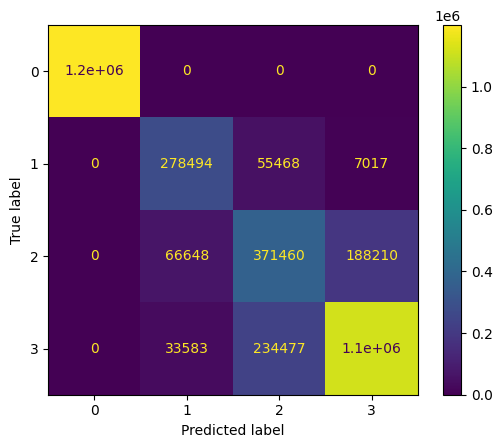


Classification Report:
               precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000   1199210
           1     0.7353    0.8167    0.7739    340979
           2     0.5616    0.5931    0.5769    626318
           3     0.8513    0.8066    0.8283   1385922

    accuracy                         0.8352   3552429
   macro avg     0.7871    0.8041    0.7948   3552429
weighted avg     0.8393    0.8352    0.8367   3552429



In [ ]:
model_rf=joblib.load('Saved_Models/model_rf.pkl')

y_pred_prob_rf = model_rf.predict_proba(X_test_feat_all)
y_pred_labels_rf = model_rf.predict(X_test_feat_all)

ConfusionMatrixDisplay.from_predictions(Y_test_all, y_pred_labels_rf)
plt.show()
print("\nClassification Report:\n", classification_report(Y_test_all, y_pred_labels_rf, digits=4))

In [ ]:
lower_CI = []
upper_CI = []
F1_macro = []
Rec_macro = []
Pre_macro = []
PR_AUC_macro = []

F1_class = []
Rec_class = []
Pre_class = []
PR_AUC_class = []
PR_AVG_class = []
PR_AUC_Mac = []

average_precisions = []
PRauc_scores = []


y_pred_prob= y_pred_prob_rf
y_pred_labels = y_pred_labels_rf


# Predict class labels

f1_score_mac = f1_score(Y_test_all, y_pred_labels, average='macro')
F1_macro.append(f1_score_mac)

rec_scores_mac = recall_score(Y_test_all, y_pred_labels, average='macro')
Rec_macro.append(rec_scores_mac)

pre_scores_mac = precision_score(Y_test_all, y_pred_labels, average='macro')
Pre_macro.append(pre_scores_mac)

f1_scores = f1_score(Y_test_all, y_pred_labels, average=None, labels=np.arange(4))
F1_class.append(f1_scores)

rec_scores = recall_score(Y_test_all, y_pred_labels, average=None, labels=np.arange(4))
Rec_class.append(rec_scores)

pre_scores = precision_score(Y_test_all, y_pred_labels, average=None, labels=np.arange(4))
Pre_class.append(pre_scores)

classes = set(Y_test_all)
for n_cl, cl in enumerate(classes):  
        f_pre, f_rec, t = precision_recall_curve(Y_test_rs[:, cl], y_pred_prob[:, cl])
        sorted_indices = np.argsort(f_rec)
        pr_auc_scores = auc(f_rec, f_pre)
        ap_score = average_precision_score(Y_test_rs[:, cl], y_pred_prob[:, cl])
        average_precisions.append(ap_score)
        PRauc_scores.append(pr_auc_scores)

PR_AVG_class.append(average_precisions)
PR_AVG_scores_mac = np.mean(average_precisions)


PR_AUC_class.append(PRauc_scores)
PRAUC_mean = np.mean(PRauc_scores)
PR_AUC_Mac.append(PRAUC_mean)

print(f"Class PR AUC: {PR_AUC_class}")
print(f"Mac PR AUC: ({PR_AUC_Mac})")


with open("RF_OS.txt", "w") as f:

    f.write("Macro F1 Measure:")
    f.write(", ".join([f"{score:.4f}" for score in F1_macro]) + "\n")
    f.write(f"Mean Macro F1 Measure: {np.mean(F1_macro):.4f}" +"\n")

    f.write("Macro Recall:")
    f.write(", ".join([f"{score:.4f}" for score in Rec_macro]) + "\n")
    f.write(f"Mean Macro Recall: {np.mean(Rec_macro):.4f}" +"\n")

    f.write("Macro Precision:")
    f.write(", ".join([f"{score:.4f}" for score in Pre_macro]) + "\n")
    f.write(f"Mean Macro Precision: {np.mean(Pre_macro):.4f}" +"\n")

    f.write("Macro PR AUC:")
    f.write(", ".join([f"{score:.4f}" for score in PR_AUC_Mac]) + "\n")
    f.write(f"Mean Macro PR AUC: {np.mean(PR_AUC_Mac):.4f}" +"\n")

    f.write("F1 Measure per Class:")
    f.write(", ".join([f"{score}" for score in F1_class]) + "\n\n")

    f.write("Recall per Class:")
    f.write(", ".join([f"{score}" for score in Rec_class]) + "\n\n")

    f.write("Precision per Class:") 
    f.write(", ".join([f"{score}" for score in Pre_class]) + "\n\n")

    f.write("PR AUC per Class:")
    f.write(", ".join([f"{score}" for score in PR_AUC_class]) + "\n\n")

    f.write("AVG PR per Class:")
    f.write(", ".join([f"{score}" for score in PR_AVG_class]) + "\n\n")

## LightGBM

In [ ]:
a = [
 'GlucoseCGM', 'diff_5', 'diff_10', 'diff_20', 'diff_40', 'GlucoseCGM_mean_30min', 'GlucoseCGM_std_30min', 'GlucoseCGM_min_30min', 'GlucoseCGM_max_30min', 'n_30min', 'time_below70_30min', 'time_above200_30min', 'diff_30min', 'slope_30min', 'GlucoseCGM_mean_1hr',
 'GlucoseCGM_std_1hr', 'GlucoseCGM_min_1hr', 'GlucoseCGM_max_1hr', 'n_1hr', 'time_below70_1hr', 'time_above200_1hr', 'diff_1hr', 'slope_1hr', 'GlucoseCGM_mean_2hr', 'GlucoseCGM_std_2hr', 'GlucoseCGM_min_2hr', 'GlucoseCGM_max_2hr', 'n_2hr', 'time_below70_2hr', 'time_above200_2hr', 'diff_2hr', 'slope_2hr', 'GlucoseCGM_mean_4hr', 'GlucoseCGM_std_4hr',  'GlucoseCGM_min_4hr', 'GlucoseCGM_max_4hr', 'n_4hr', 'time_below70_4hr',
 'time_above200_4hr', 'diff_4hr', 'slope_4hr', 'GlucoseCGM_mean_8hr', 'GlucoseCGM_std_8hr', 'GlucoseCGM_min_8hr', 'GlucoseCGM_max_8hr', 'n_8hr', 'time_below70_8hr',
 'time_above200_8hr', 'diff_8hr', 'slope_8hr', 'GlucoseCGM_mean_24hr', 'GlucoseCGM_std_24hr', 'GlucoseCGM_min_24hr', 'GlucoseCGM_max_24hr', 'n_24hr', 'time_below70_24hr',  'time_above200_24hr',  'diff_24hr', 'slope_24hr', 'hypo_points_30m', 'avg_event_duration_min_30m', 'min_since_last_event_30m', 'hypo_points_1h', 'avg_event_duration_min_1h', 'min_since_last_event_1h', 'hypo_points_2h', 'avg_event_duration_min_2h', 'min_since_last_event_2h', 'hypo_points_4h', 'avg_event_duration_min_4h', 'min_since_last_event_4h',  'hypo_points_24h', 'avg_event_duration_min_24h', 'min_since_last_event_24h', 'hour', 'minute', 'dayofweek', 'valid_30min', 'valid_1hr', 'valid_2hr', 'valid_4hr',  'valid_8hr', 'valid_24hr',]

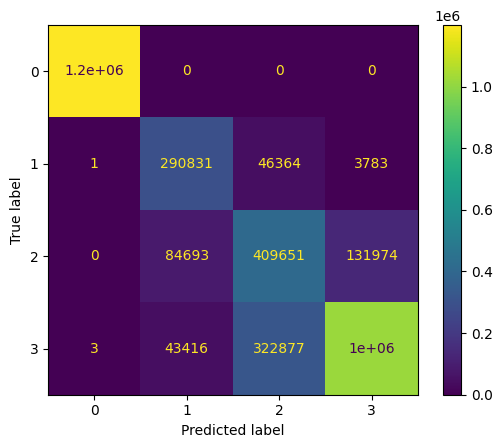


Classification Report:
               precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000   1199210
           1     0.6942    0.8529    0.7654    340979
           2     0.5259    0.6541    0.5830    626318
           3     0.8825    0.7357    0.8024   1385922

    accuracy                         0.8218   3552429
   macro avg     0.7757    0.8107    0.7877   3552429
weighted avg     0.8412    0.8218    0.8269   3552429



In [ ]:
model_lbgm= joblib.load('Saved_Models/model_lgm.pkl')
X_test_feat_all_df = pd.DataFrame(X_test_feat_all, columns=a)

y_pred_labels_lbgm = model_lbgm.predict(X_test_feat_all_df)
y_pred_prob_lbgm = model_lbgm.predict_proba(X_test_feat_all_df)
ConfusionMatrixDisplay.from_predictions(Y_test_all, y_pred_labels_lbgm)
plt.show()

print("\nClassification Report:\n", classification_report(Y_test_all, y_pred_labels_lbgm, digits=4))

In [ ]:
lower_CI = []
upper_CI = []
F1_macro = []
Rec_macro = []
Pre_macro = []
PR_AUC_macro = []

F1_class = []
Rec_class = []
Pre_class = []
PR_AUC_class = []
PR_AVG_class = []
PR_AUC_Mac = []

average_precisions = []
PRauc_scores = []


y_pred_prob= y_pred_prob_lbgm
y_pred_labels = y_pred_labels_lbgm
y_pred_labels_rf


# Predict class labels

f1_score_mac = f1_score(Y_test_all, y_pred_labels, average='macro')
F1_macro.append(f1_score_mac)

rec_scores_mac = recall_score(Y_test_all, y_pred_labels, average='macro')
Rec_macro.append(rec_scores_mac)

pre_scores_mac = precision_score(Y_test_all, y_pred_labels, average='macro')
Pre_macro.append(pre_scores_mac)

f1_scores = f1_score(Y_test_all, y_pred_labels, average=None, labels=np.arange(4))
F1_class.append(f1_scores)

rec_scores = recall_score(Y_test_all, y_pred_labels, average=None, labels=np.arange(4))
Rec_class.append(rec_scores)

pre_scores = precision_score(Y_test_all, y_pred_labels, average=None, labels=np.arange(4))
Pre_class.append(pre_scores)

classes = set(Y_test_all)
for n_cl, cl in enumerate(classes):  
        f_pre, f_rec, t = precision_recall_curve(Y_test_rs[:, cl], y_pred_prob[:, cl])
        sorted_indices = np.argsort(f_rec)
        pr_auc_scores = auc(f_rec, f_pre)
        ap_score = average_precision_score(Y_test_rs[:, cl], y_pred_prob[:, cl])
        average_precisions.append(ap_score)
        PRauc_scores.append(pr_auc_scores)

PR_AVG_class.append(average_precisions)
PR_AVG_scores_mac = np.mean(average_precisions)


PR_AUC_class.append(PRauc_scores)
PRAUC_mean = np.mean(PRauc_scores)
PR_AUC_Mac.append(PRAUC_mean)

print(f"Class PR AUC: {PR_AUC_class}")
print(f"Mac PR AUC: ({PR_AUC_Mac})")



with open("LGBM_OS.txt", "w") as f:

    f.write("Macro F1 Measure:")
    f.write(", ".join([f"{score:.4f}" for score in F1_macro]) + "\n")
    f.write(f"Mean Macro F1 Measure: {np.mean(F1_macro):.4f}" +"\n")

    f.write("Macro Recall:")
    f.write(", ".join([f"{score:.4f}" for score in Rec_macro]) + "\n")
    f.write(f"Mean Macro Recall: {np.mean(Rec_macro):.4f}" +"\n")

    f.write("Macro Precision:")
    f.write(", ".join([f"{score:.4f}" for score in Pre_macro]) + "\n")
    f.write(f"Mean Macro Precision: {np.mean(Pre_macro):.4f}" +"\n")

    f.write("Macro PR AUC:")
    f.write(", ".join([f"{score:.4f}" for score in PR_AUC_Mac]) + "\n")
    f.write(f"Mean Macro PR AUC: {np.mean(PR_AUC_Mac):.4f}" +"\n")

    f.write("F1 Measure per Class:")
    f.write(", ".join([f"{score}" for score in F1_class]) + "\n\n")

    f.write("Recall per Class:")
    f.write(", ".join([f"{score}" for score in Rec_class]) + "\n\n")

    f.write("Precision per Class:") 
    f.write(", ".join([f"{score}" for score in Pre_class]) + "\n\n")

    f.write("PR AUC per Class:")
    f.write(", ".join([f"{score}" for score in PR_AUC_class]) + "\n\n")

    f.write("AVG PR per Class:")
    f.write(", ".join([f"{score}" for score in PR_AVG_class]) + "\n\n")

## TCN

In [ ]:
X_train, Y_train = load("Data/DataTrain_Multiclass_DL.joblib")

# ensures reproducability
seed_value= 42  
os.environ['PYTHONHASHSEED']=str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)


# assuming X_data and Y_data are lists (or arrays) where each entry corresponds to one subject
subject_indices = list(range(len(Y_train)))


# split into temp and test (20%)
train_idx, abl_idx = train_test_split(subject_indices, test_size=0.05, shuffle=True, random_state=seed_value)


X_train_fold = [X_train[i] for i in train_idx]
Y_train_fold = [Y_train[i] for i in train_idx]


print(len(train_idx))

# flattens the arrays of single subjects into one array of shape (X,25,2)
Y_train_fold  =flatten(Y_train_fold)
Y_train_fold= Y_train_fold.reshape(-1)

# flattens the arrays of single subjects into one array of shape (X,1)
X_train_fold = flatten(X_train_fold)


print(X_train_fold.shape)

BATCH_SIZE =  256  
BUFFER_SIZE = min(len(X_train_fold), 10_000)
SEED = 42

Y_train_rs = to_categorical(Y_train_fold)
Y_test_rs = to_categorical(Y_test_fold)
# for class weights 
Y_train_weights = Y_train_fold.reshape(-1).astype('int32')

# converts train, val, and test data into tensors
X_train_t = tf.convert_to_tensor(X_train_fold, dtype=tf.float32)
Y_train_t = tf.convert_to_tensor(Y_train_rs, dtype=tf.int32)


# shuffles train data and applies batch size 
train_ds_t = tf.data.Dataset.from_tensor_slices((X_train_t, Y_train_t))
train_ds = train_ds_t.shuffle(BUFFER_SIZE, seed=SEED).batch(BATCH_SIZE).prefetch(1)

Y_train_all = Y_train_fold.reshape(-1)

1906
(12891361, 25, 1)


111014/111014 ━━━━━━━━━━━━━━━━━━━━ 640s 6ms/step


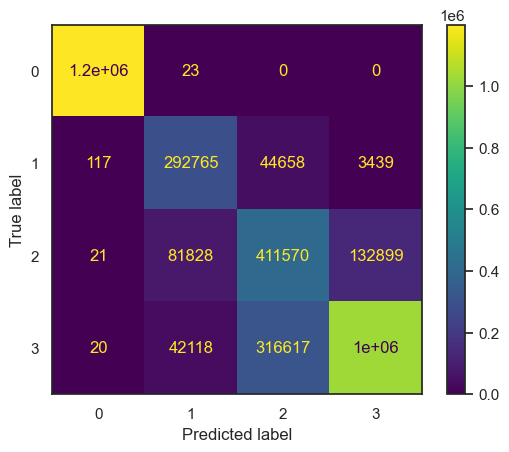

              precision    recall  f1-score   support

           0     0.9999    1.0000    0.9999   1199210
           1     0.7025    0.8586    0.7728    340979
           2     0.5325    0.6571    0.5883    626318
           3     0.8828    0.7411    0.8058   1385922

    accuracy                         0.8250   3552429
   macro avg     0.7794    0.8142    0.7917   3552429
weighted avg     0.8433    0.8250    0.8298   3552429



In [ ]:
model_tcn = load_model("Saved_Models/TCN_model_OS.keras")


sns.set_theme(style="white")
# evaluates the model and plots the confusion matrix
predictions_tcn = model_tcn.predict(X_test_t)

y_pred_tcn = np.argmax(predictions_tcn, axis=1) 
    

final_preds_tcn = y_pred_tcn

y_true_labels_tcn = np.argmax(Y_test_t, axis=1)
ConfusionMatrixDisplay.from_predictions(y_true_labels_tcn, final_preds_tcn)
plt.show()

report_tcn = classification_report(y_true_labels_tcn, final_preds_tcn, digits=4)
print(report_tcn)

In [ ]:
lower_CI = []
upper_CI = []
F1_macro = []
Rec_macro = []
Pre_macro = []
PR_AUC_macro = []

F1_class = []
Rec_class = []
Pre_class = []
PR_AUC_class = []
PR_AVG_class = []
PR_AUC_Mac = []

average_precisions = []
PRauc_scores = []


y_pred_prob= predictions_tcn
y_pred_labels = y_pred_tcn


# Predict class labels

f1_score_mac = f1_score(Y_test_all, y_pred_labels, average='macro')
F1_macro.append(f1_score_mac)

rec_scores_mac = recall_score(Y_test_all, y_pred_labels, average='macro')
Rec_macro.append(rec_scores_mac)

pre_scores_mac = precision_score(Y_test_all, y_pred_labels, average='macro')
Pre_macro.append(pre_scores_mac)

f1_scores = f1_score(Y_test_all, y_pred_labels, average=None, labels=np.arange(4))
F1_class.append(f1_scores)

rec_scores = recall_score(Y_test_all, y_pred_labels, average=None, labels=np.arange(4))
Rec_class.append(rec_scores)

pre_scores = precision_score(Y_test_all, y_pred_labels, average=None, labels=np.arange(4))
Pre_class.append(pre_scores)

classes = set(Y_test_all)
for n_cl, cl in enumerate(classes):  
        f_pre, f_rec, t = precision_recall_curve(Y_test_rs[:, cl], y_pred_prob[:, cl])
        sorted_indices = np.argsort(f_rec)
        pr_auc_scores = auc(f_rec, f_pre)
        ap_score = average_precision_score(Y_test_rs[:, cl], y_pred_prob[:, cl])
        average_precisions.append(ap_score)
        PRauc_scores.append(pr_auc_scores)

PR_AVG_class.append(average_precisions)
PR_AVG_scores_mac = np.mean(average_precisions)


PR_AUC_class.append(PRauc_scores)
PRAUC_mean = np.mean(PRauc_scores)
PR_AUC_Mac.append(PRAUC_mean)

print(f"Class PR AUC: {PR_AUC_class}")
print(f"Mac PR AUC: ({PR_AUC_Mac})")



with open("TCN_OS.txt", "w") as f:

    f.write("Macro F1 Measure:")
    f.write(", ".join([f"{score:.4f}" for score in F1_macro]) + "\n")
    f.write(f"Mean Macro F1 Measure: {np.mean(F1_macro):.4f}" +"\n")

    f.write("Macro Recall:")
    f.write(", ".join([f"{score:.4f}" for score in Rec_macro]) + "\n")
    f.write(f"Mean Macro Recall: {np.mean(Rec_macro):.4f}" +"\n")

    f.write("Macro Precision:")
    f.write(", ".join([f"{score:.4f}" for score in Pre_macro]) + "\n")
    f.write(f"Mean Macro Precision: {np.mean(Pre_macro):.4f}" +"\n")

    f.write("Macro PR AUC:")
    f.write(", ".join([f"{score:.4f}" for score in PR_AUC_Mac]) + "\n")
    f.write(f"Mean Macro PR AUC: {np.mean(PR_AUC_Mac):.4f}" +"\n")

    f.write("F1 Measure per Class:")
    f.write(", ".join([f"{score}" for score in F1_class]) + "\n\n")

    f.write("Recall per Class:")
    f.write(", ".join([f"{score}" for score in Rec_class]) + "\n\n")

    f.write("Precision per Class:") 
    f.write(", ".join([f"{score}" for score in Pre_class]) + "\n\n")

    f.write("PR AUC per Class:")
    f.write(", ".join([f"{score}" for score in PR_AUC_class]) + "\n\n")

    f.write("AVG PR per Class:")
    f.write(", ".join([f"{score}" for score in PR_AVG_class]) + "\n\n")

## TCN MHAL

111014/111014 ━━━━━━━━━━━━━━━━━━━━ 659s 6ms/step


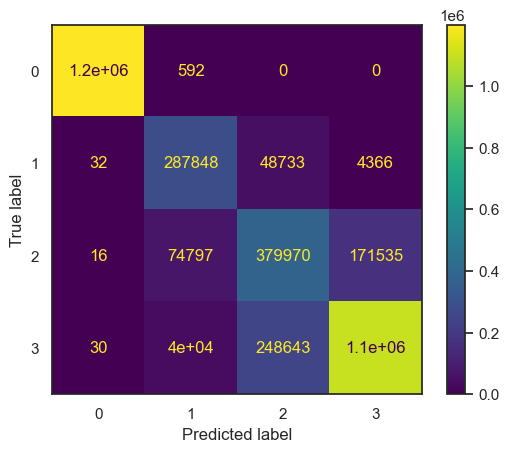

              precision    recall  f1-score   support

           0     0.9999    0.9995    0.9997   1199210
           1     0.7140    0.8442    0.7736    340979
           2     0.5610    0.6067    0.5829    626318
           3     0.8618    0.7918    0.8253   1385922

    accuracy                         0.8343   3552429
   macro avg     0.7842    0.8105    0.7954   3552429
weighted avg     0.8412    0.8343    0.8365   3552429



In [ ]:
model_tcn_mhal = load_model("Saved_Models/TCN_model_MHAL_OS.keras")

sns.set_theme(style="white")
# evaluates the model and plots the confusion matrix
predictions_tcn_mhal = model_tcn_mhal.predict(X_test_t)

y_pred_tcn_mhal = np.argmax(predictions_tcn_mhal, axis=1) 
    
final_preds_tcn_mhal = y_pred_tcn_mhal


y_true_labels_tcn_mhal = np.argmax(Y_test_t, axis=1)
ConfusionMatrixDisplay.from_predictions(y_true_labels_tcn_mhal, final_preds_tcn_mhal)
plt.show()

report_fcn_tcn_mhal = classification_report(y_true_labels_tcn_mhal, final_preds_tcn_mhal, digits=4)
print(report_fcn_tcn_mhal)

In [ ]:
lower_CI = []
upper_CI = []
F1_macro = []
Rec_macro = []
Pre_macro = []
PR_AUC_macro = []

F1_class = []
Rec_class = []
Pre_class = []
PR_AUC_class = []
PR_AVG_class = []
PR_AUC_Mac = []

average_precisions = []
PRauc_scores = []


y_pred_prob= predictions_tcn_mhal
y_pred_labels = y_pred_tcn_mhal


# Predict class labels

f1_score_mac = f1_score(Y_test_all, y_pred_labels, average='macro')
F1_macro.append(f1_score_mac)

rec_scores_mac = recall_score(Y_test_all, y_pred_labels, average='macro')
Rec_macro.append(rec_scores_mac)

pre_scores_mac = precision_score(Y_test_all, y_pred_labels, average='macro')
Pre_macro.append(pre_scores_mac)

f1_scores = f1_score(Y_test_all, y_pred_labels, average=None, labels=np.arange(4))
F1_class.append(f1_scores)

rec_scores = recall_score(Y_test_all, y_pred_labels, average=None, labels=np.arange(4))
Rec_class.append(rec_scores)

pre_scores = precision_score(Y_test_all, y_pred_labels, average=None, labels=np.arange(4))
Pre_class.append(pre_scores)

classes = set(Y_test_all)
for n_cl, cl in enumerate(classes):  
        f_pre, f_rec, t = precision_recall_curve(Y_test_rs[:, cl], y_pred_prob[:, cl])
        sorted_indices = np.argsort(f_rec)
        pr_auc_scores = auc(f_rec, f_pre)
        ap_score = average_precision_score(Y_test_rs[:, cl], y_pred_prob[:, cl])
        average_precisions.append(ap_score)
        PRauc_scores.append(pr_auc_scores)

PR_AVG_class.append(average_precisions)
PR_AVG_scores_mac = np.mean(average_precisions)


PR_AUC_class.append(PRauc_scores)
PRAUC_mean = np.mean(PRauc_scores)
PR_AUC_Mac.append(PRAUC_mean)

print(f"Class PR AUC: {PR_AUC_class}")
print(f"Mac PR AUC: ({PR_AUC_Mac})")



with open("TCN_MHAL_OS.txt", "w") as f:

    f.write("Macro F1 Measure:")
    f.write(", ".join([f"{score:.4f}" for score in F1_macro]) + "\n")
    f.write(f"Mean Macro F1 Measure: {np.mean(F1_macro):.4f}" +"\n")

    f.write("Macro Recall:")
    f.write(", ".join([f"{score:.4f}" for score in Rec_macro]) + "\n")
    f.write(f"Mean Macro Recall: {np.mean(Rec_macro):.4f}" +"\n")

    f.write("Macro Precision:")
    f.write(", ".join([f"{score:.4f}" for score in Pre_macro]) + "\n")
    f.write(f"Mean Macro Precision: {np.mean(Pre_macro):.4f}" +"\n")

    f.write("Macro PR AUC:")
    f.write(", ".join([f"{score:.4f}" for score in PR_AUC_Mac]) + "\n")
    f.write(f"Mean Macro PR AUC: {np.mean(PR_AUC_Mac):.4f}" +"\n")

    f.write("F1 Measure per Class:")
    f.write(", ".join([f"{score}" for score in F1_class]) + "\n\n")

    f.write("Recall per Class:")
    f.write(", ".join([f"{score}" for score in Rec_class]) + "\n\n")

    f.write("Precision per Class:") 
    f.write(", ".join([f"{score}" for score in Pre_class]) + "\n\n")

    f.write("PR AUC per Class:")
    f.write(", ".join([f"{score}" for score in PR_AUC_class]) + "\n\n")

    f.write("AVG PR per Class:")
    f.write(", ".join([f"{score}" for score in PR_AVG_class]) + "\n\n")

## GAT

In [ ]:
device = torch.device("cpu")

GAT_model = NVG_GATv2(num_classes=4).to(device)

GAT_model.load_state_dict(
    torch.load(
        "/Saved_Models/GATv2_OS.pt",
        map_location="cpu",
        weights_only=True
    )
)

torch.set_num_threads(1)
GAT_model.eval()

NVG_GATv2(
  (node_dense): Linear(in_features=3, out_features=64, bias=True)
  (edge_dense): Linear(in_features=1, out_features=8, bias=True)
  (gatv2conv1): GATv2Conv(64, 8, heads=6)
  (bn1): BatchNorm1d(48, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (gatv2conv2): GATv2Conv(48, 8, heads=6)
  (bn2): BatchNorm1d(48, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (classifier): Linear(in_features=48, out_features=4, bias=True)
)

In [ ]:
Test_loader = create_nvg_dataset(
    X_test_fold,
    X_DL_Avg,
    Y_test_cat_pt,
    batch_size=128,
    shuffle=False,
    rand_seed=42
)

GAT_y_true = []
GAT_y_pred = []
GAT_y_prob = []

In [ ]:
with torch.inference_mode():
    for batch in tqdm(Test_loader, desc="GATv2 Evaluation", unit="batch"):

        logits = GAT_model(batch.to("cpu"))
        probabilities = torch.softmax(logits, dim=1)

        GAT_y_true.append(batch.y.numpy())
        GAT_y_pred.append(probabilities.argmax(dim=1).numpy())
        GAT_y_prob.append(probabilities.numpy())

GAT_y_true = np.concatenate(GAT_y_true)
GAT_y_pred = np.concatenate(GAT_y_pred)
GAT_y_prob = np.concatenate(GAT_y_prob)

print(
    classification_report(
        GAT_y_true,
        GAT_y_pred,
        labels=[0, 1, 2, 3],
        digits=4,
        zero_division=0
    )
)

# Confusion matrix
sns.set_theme(style="white")

ConfusionMatrixDisplay.from_predictions(
    GAT_y_true,
    GAT_y_pred,
    labels=[0, 1, 2, 3],
    values_format="d"
)

plt.title(f"GAT Confusion Matrix")
plt.tight_layout()
plt.show()

GATv2 Evaluation: 100%|██████████| 27754/27754 [19:17<00:00, 23.98batch/s]


              precision    recall  f1-score   support

           0     0.9996    1.0000    0.9998   1199210
           1     0.7112    0.8360    0.7685    340979
           2     0.5214    0.6630    0.5837    626318
           3     0.8810    0.7346    0.8012   1385922

    accuracy                         0.8213   3552429
   macro avg     0.7783    0.8084    0.7883   3552429
weighted avg     0.8414    0.8213    0.8268   3552429



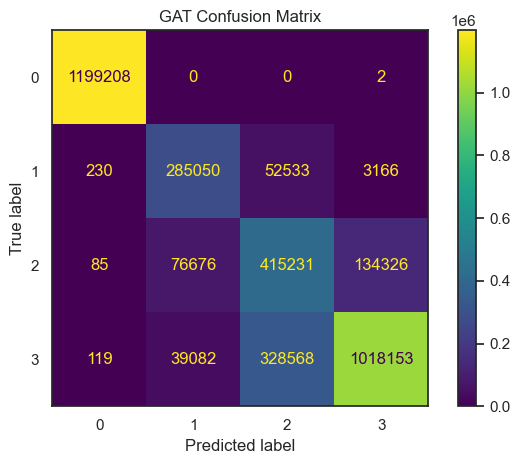

In [ ]:
print(
    classification_report(
        GAT_y_true,
        GAT_y_pred,
        labels=[0, 1, 2, 3],
        digits=4,
        zero_division=0
    )
)

# Confusion matrix
sns.set_theme(style="white")

ConfusionMatrixDisplay.from_predictions(
    GAT_y_true,
    GAT_y_pred,
    labels=[0, 1, 2, 3],
    values_format="d"
)

plt.title(f"GAT Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
folder = Path("/Outputs/joblib")

GAT_true = []
GAT_proba = []

for fold in range(3):

    Y_test_fold_gat = load(
        folder / f"y_true_GATv2_fold_{fold}.joblib"
    )

    y_pred_prob_gat = load(
        folder / f"y_pred_prob_GATv2_fold_{fold}.joblib"
    )

    # Same as original ResNet code
    GAT_true.append(Y_test_fold_gat)
    GAT_proba.append(y_pred_prob_gat)

    dump(GAT_true, folder / "y_true_GAT.joblib")
    dump(GAT_proba, folder / "y_pred_prob_GAT.joblib")

In [ ]:
y_pred_prob = np.asarray(GAT_y_prob)
y_pred_labels = np.asarray(GAT_y_pred).reshape(-1)

assert len(Y_test_all) == len(y_pred_labels) == len(y_pred_prob)
assert y_pred_prob.shape[1] == 4

lower_CI = []
upper_CI = []
F1_macro = []
Rec_macro = []
Pre_macro = []
PR_AUC_macro = []

F1_class = []
Rec_class = []
Pre_class = []
PR_AUC_class = []
PR_AVG_class = []
PR_AUC_Mac = []

average_precisions = []
PRauc_scores = []

f1_score_mac = f1_score(Y_test_all, y_pred_labels, average='macro')
F1_macro.append(f1_score_mac)

rec_scores_mac = recall_score(Y_test_all, y_pred_labels, average='macro')
Rec_macro.append(rec_scores_mac)

pre_scores_mac = precision_score(Y_test_all, y_pred_labels, average='macro')
Pre_macro.append(pre_scores_mac)

f1_scores = f1_score(
    Y_test_all, y_pred_labels,
    average=None, labels=np.arange(4)
)
F1_class.append(f1_scores)

rec_scores = recall_score(
    Y_test_all, y_pred_labels,
    average=None, labels=np.arange(4)
)
Rec_class.append(rec_scores)

pre_scores = precision_score(
    Y_test_all, y_pred_labels,
    average=None, labels=np.arange(4)
)
Pre_class.append(pre_scores)

for cl in range(4):

    f_pre, f_rec, t = precision_recall_curve(
        Y_test_rs[:, cl],
        y_pred_prob[:, cl]
    )

    pr_auc_scores = auc(f_rec, f_pre)

    ap_score = average_precision_score(
        Y_test_rs[:, cl],
        y_pred_prob[:, cl]
    )

    average_precisions.append(ap_score)
    PRauc_scores.append(pr_auc_scores)

PR_AVG_class.append(average_precisions)
PR_AVG_scores_mac = np.mean(average_precisions)

PR_AUC_class.append(PRauc_scores)
PRAUC_mean = np.mean(PRauc_scores)
PR_AUC_Mac.append(PRAUC_mean)

print(f"Class PR AUC: {PR_AUC_class}")
print(f"Mac PR AUC: ({PR_AUC_Mac})")

with open("GATv2_OS.txt", "w") as f:

    f.write("Macro F1 Measure:")
    f.write(", ".join([f"{score:.4f}" for score in F1_macro]) + "\n")
    f.write(f"Mean Macro F1 Measure: {np.mean(F1_macro):.4f}" + "\n")

    f.write("Macro Recall:")
    f.write(", ".join([f"{score:.4f}" for score in Rec_macro]) + "\n")
    f.write(f"Mean Macro Recall: {np.mean(Rec_macro):.4f}" + "\n")

    f.write("Macro Precision:")
    f.write(", ".join([f"{score:.4f}" for score in Pre_macro]) + "\n")
    f.write(f"Mean Macro Precision: {np.mean(Pre_macro):.4f}" + "\n")

    f.write("Macro PR AUC:")
    f.write(", ".join([f"{score:.4f}" for score in PR_AUC_Mac]) + "\n")
    f.write(f"Mean Macro PR AUC: {np.mean(PR_AUC_Mac):.4f}" + "\n")

    f.write("F1 Measure per Class:")
    f.write(", ".join([f"{score}" for score in F1_class]) + "\n\n")

    f.write("Recall per Class:")
    f.write(", ".join([f"{score}" for score in Rec_class]) + "\n\n")

    f.write("Precision per Class:")
    f.write(", ".join([f"{score}" for score in Pre_class]) + "\n\n")

    f.write("PR AUC per Class:")
    f.write(", ".join([f"{score}" for score in PR_AUC_class]) + "\n\n")

    f.write("AVG PR per Class:")
    f.write(", ".join([f"{score}" for score in PR_AVG_class]) + "\n\n")

## Ensemble Stacking 

In [ ]:
RF_true = load("Outputs/y_true_RF.joblib")
RF_proba = flatten(load("Outputs/y_pred_prob_RF.joblib"))

LightGBM_true = load("Outputs/y_true_LBG1.joblib")
LightGBM_proba = flatten(load("Outputs/y_pred_prob_LBG1.joblib"))

TCN_true = load("Outputs/y_true_TCN.joblib")
TCN_proba = flatten(load("Outputs/y_pred_prob_TCN.joblib"))

TCN_MHAL_true = load("Outputs/y_true_TCN_MH.joblib")
TCN_MHAL_proba = flatten(load("Outputs/y_pred_prob_TCN_MH.joblib"))

GAT_true = load("Outputs/y_true_GAT.joblib")
GAT_proba = flatten(load("Outputs/y_pred_prob_GAT.joblib"))

Number of ensemble combinations: 26


Ensemble Ablation: 100%|██████████| 26/26 [1:03:50<00:00, 147.35s/it]


=== ENSEMBLE ABLATION RESULTS ===


,Models,N_models,Recall,Precision,F1-score,PR-AUC
0,RF + LightGBM + TCN+MHAL,3,0.8137,0.7868,0.7977,0.8493
1,RF + LightGBM + TCN+MHAL + GAT,4,0.8137,0.7867,0.7977,0.8494
2,RF + TCN+MHAL,2,0.8128,0.7868,0.7976,0.8492
3,RF + TCN+MHAL + GAT,3,0.8129,0.7867,0.7976,0.8492
4,LightGBM + TCN+MHAL + GAT,3,0.8136,0.7865,0.7976,0.8492
5,LightGBM + TCN+MHAL,2,0.8136,0.7863,0.7975,0.8492
6,TCN+MHAL + GAT,2,0.8116,0.7859,0.7968,0.8483
7,RF + TCN + TCN+MHAL + GAT,4,0.8149,0.7848,0.7966,0.8493
8,RF + LightGBM + TCN + TCN+MHAL + GAT,5,0.8156,0.7848,0.7965,0.8494
9,LightGBM + TCN + TCN+MHAL,3,0.8153,0.7848,0.7964,0.8494



=== BEST ENSEMBLE PER METRIC ===


,Metric,Best combination,Score
0,Recall,RF + LightGBM + TCN + TCN+MHAL,0.8156
1,Precision,RF + LightGBM + TCN+MHAL,0.7868
2,F1-score,RF + LightGBM + TCN+MHAL,0.7977
3,PR-AUC,LightGBM + TCN + TCN+MHAL,0.8494



=== BEST ENSEMBLE (MACRO F1) ===
Models: LightGBM + TCN + TCN+MHAL
Macro Recall:    0.8137
Macro Precision: 0.7868
Macro F1-score:  0.7977
Macro PR-AUC:    0.8493

=== BEST ENSEMBLE CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000   1199210
           1     0.7174    0.8518    0.7788    340979
           2     0.5440    0.6481    0.5915    626318
           3     0.8777    0.7613    0.8154   1385922

    accuracy                         0.8306   3552429
   macro avg     0.7848    0.8153    0.7964   3552429
weighted avg     0.8448    0.8306    0.8347   3552429



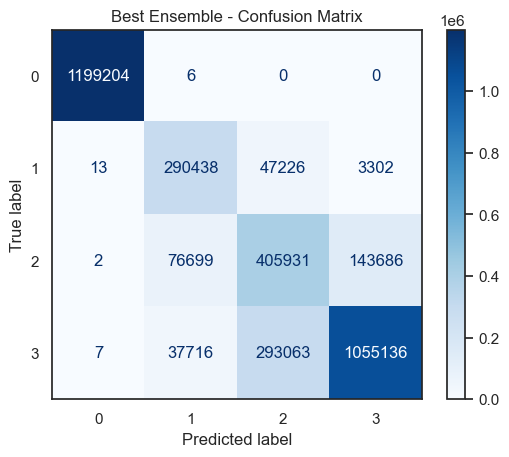

In [ ]:
# ensures reproducability
seed_value= 42  
os.environ['PYTHONHASHSEED']=str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)
tf.compat.v1.set_random_seed(seed_value)


# =========================================================
# Validation probabilities (training the meta-learner)
# =========================================================

val_models_proba = {
    "RF": np.asarray(RF_proba),
    "LightGBM": np.asarray(LightGBM_proba),
    "TCN": np.asarray(TCN_proba),
    "TCN+MHAL": np.asarray(TCN_MHAL_proba),
    "GAT": np.asarray(flatten(GAT_proba))
}

y_val = np.asarray(flatten(RF_true)).reshape(-1)


# =========================================================
# Test probabilities
# =========================================================

test_models_proba = {
    "RF": np.asarray(y_pred_prob_rf),
    "LightGBM": np.asarray(y_pred_prob_lbgm),
    "TCN": np.asarray(predictions_tcn),
    "TCN+MHAL": np.asarray(predictions_tcn_mhal),
    "GAT": np.asarray(GAT_y_prob)
}

y_test = np.argmax(Y_test_t, axis=1)


# Verify shapes
for name in val_models_proba:
    assert val_models_proba[name].shape == (len(y_val), 4), (
        f"Validation shape mismatch: {name}"
    )
    assert test_models_proba[name].shape == (len(y_test), 4), (
        f"Test shape mismatch: {name}"
    )


# =========================================================
# Generate all combinations (2 to 5 models)
# =========================================================

model_names = list(val_models_proba.keys())

combinations = [
    combo
    for n in range(2, len(model_names) + 1)
    for combo in itertools.combinations(model_names, n)
]

print(f"Number of ensemble combinations: {len(combinations)}")


# =========================================================
# Train and evaluate each combination
# =========================================================

results = []

best_pr_auc = -np.inf
best_recall = -np.inf
best_meta = None
best_combo = None
best_pred = None
best_prob = None

for combo in tqdm(combinations, desc="Ensemble Ablation"):

    # Validation inputs
    X_meta_val = np.hstack([val_models_proba[name] for name in combo])

    # Test inputs
    X_meta_test = np.hstack([test_models_proba[name] for name in combo])

    # Same meta-learner as original code
    meta = LogisticRegression(
        solver="lbfgs",
        max_iter=500,
        C=1.0,
        class_weight="balanced",
        random_state=42
    )

    meta.fit(X_meta_val, y_val)

    # Test predictions
    P_ens_test = meta.predict_proba(X_meta_test)
    y_pred = meta.classes_[P_ens_test.argmax(axis=1)]

    # Macro metrics
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    # Macro PR-AUC
    pr_auc_scores = []

    for i, cl in enumerate(meta.classes_):
        f_pre, f_rec, _ = precision_recall_curve(
            (y_test == cl).astype(int),
            P_ens_test[:, i]
        )

        pr_auc_scores.append(auc(f_rec, f_pre))

    pr_auc_macro = np.mean(pr_auc_scores)

    # Store results
    results.append({
        "Models": " + ".join(combo),
        "N_models": len(combo),
        "Recall": recall,
        "Precision": precision,
        "F1-score": f1,
        "PR-AUC": pr_auc_macro
    })

    if (pr_auc_macro, recall) > (best_pr_auc, best_recall):
        best_pr_auc = pr_auc_macro
        best_recall = recall

        best_meta = meta
        best_combo = combo
        best_pred = y_pred.copy()
        best_prob = P_ens_test.copy()


# =========================================================
# Final ablation table (sorted by F1-score)
# =========================================================

ablation_df = pd.DataFrame(results).sort_values(
    by=["PR-AUC", "Recall"],
    ascending=[False, False]
).reset_index(drop=True)

print("\n=== ENSEMBLE ABLATION RESULTS ===")
display(ablation_df.round(4))


# =========================================================
# Best ensemble for each metric
# =========================================================

best_results = []

for metric in ["Recall", "Precision", "F1-score", "PR-AUC"]:

    row = ablation_df.loc[ablation_df[metric].idxmax()]

    best_results.append({
        "Metric": metric,
        "Best combination": row["Models"],
        "Score": row[metric]
    })

best_results_df = pd.DataFrame(best_results)

print("\n=== BEST ENSEMBLE PER METRIC ===")
display(best_results_df.round(4))


# =========================================================
# Best overall ensemble (highest macro F1-score)
# =========================================================

print("\n=== BEST ENSEMBLE (MACRO PR AUC) ===")
print("Models:", " + ".join(best_combo))

best_row = ablation_df.iloc[0]

print(f"Macro Recall:    {best_row['Recall']:.4f}")
print(f"Macro Precision: {best_row['Precision']:.4f}")
print(f"Macro F1-score:  {best_row['F1-score']:.4f}")
print(f"Macro PR-AUC:    {best_row['PR-AUC']:.4f}")


# =========================================================
# Classification report for best ensemble
# =========================================================

print("\n=== BEST ENSEMBLE CLASSIFICATION REPORT ===")

print(
    classification_report(
        y_test,
        best_pred,
        labels=np.arange(4),
        digits=4,
        zero_division=0
    )
)


# =========================================================
# Confusion matrix for best ensemble
# =========================================================

ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_pred,
    labels=np.arange(4),
    values_format="d"
)

plt.title("Best Ensemble - Confusion Matrix")
plt.show()

In [ ]:
top_4 = [
    "LightGBM + TCN + TCN+MHAL",
    "LightGBM + TCN + TCN+MHAL + GAT",
    "RF + LightGBM + TCN + TCN+MHAL + GAT",
    "RF + LightGBM + TCN+MHAL + GAT"
]

selected = ablation_df[
    ablation_df["Models"].isin(top_4)
].copy()

selected["Models"] = pd.Categorical(
    selected["Models"],
    categories=top_4,
    ordered=True
)

selected = selected.sort_values("Models")

print(
    selected.to_string(
        index=False,
        float_format=lambda x: f"{x:.10f}"
    )
)

                              Models  N_models       Recall    Precision     F1-score       PR-AUC
           LightGBM + TCN + TCN+MHAL         3 0.8153047153 0.7847679264 0.7964269534 0.8494224783
     LightGBM + TCN + TCN+MHAL + GAT         4 0.8155748566 0.7845854746 0.7963570029 0.8493854026
RF + LightGBM + TCN + TCN+MHAL + GAT         5 0.8156055604 0.7848097526 0.7964908872 0.8493734093
      RF + LightGBM + TCN+MHAL + GAT         4 0.8136575147 0.7867261875 0.7976599652 0.8493586869


In [ ]:
seed_value= 42  
os.environ['PYTHONHASHSEED']=str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)
tf.compat.v1.set_random_seed(seed_value)

X_meta_val_LGBM_TCN_TMHAL = np.hstack([LightGBM_proba, TCN_proba, TCN_MHAL_proba])  
meta_LGBM_TCN_TMHAL = LogisticRegression(solver="lbfgs", max_iter=500,  C=1.0,class_weight="balanced", random_state =42)
meta_LGBM_TCN_TMHAL .fit(X_meta_val_LGBM_TCN_TMHAL, flatten(RF_true))

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:

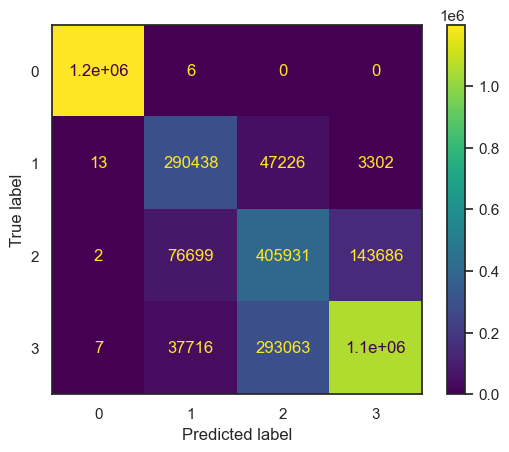

              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000   1199210
           1     0.7174    0.8518    0.7788    340979
           2     0.5440    0.6481    0.5915    626318
           3     0.8777    0.7613    0.8154   1385922

    accuracy                         0.8306   3552429
   macro avg     0.7848    0.8153    0.7964   3552429
weighted avg     0.8448    0.8306    0.8347   3552429



In [ ]:
seed_value= 42  
os.environ['PYTHONHASHSEED']=str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)
tf.compat.v1.set_random_seed(seed_value)

X_meta_test_LGBM_TCN_TMHAL = np.hstack([y_pred_prob_lbgm, predictions_tcn, predictions_tcn_mhal])  
P_ens_test_LGBM_TCN_TMHAL = meta_LGBM_TCN_TMHAL.predict_proba(X_meta_test_LGBM_TCN_TMHAL)
y_pred_LGBM_TCN_TMHAL = P_ens_test_LGBM_TCN_TMHAL.argmax(axis=1)

y_true_labels_LGBM_TCN_TMHAL = np.argmax(Y_test_t, axis=1)
ConfusionMatrixDisplay.from_predictions(y_true_labels_LGBM_TCN_TMHAL,y_pred_LGBM_TCN_TMHAL)
plt.show()

report_fcn_LGBM_TCN_TMHAL = classification_report(y_true_labels_LGBM_TCN_TMHAL, y_pred_LGBM_TCN_TMHAL, digits=4)
print(report_fcn_LGBM_TCN_TMHAL)

In [ ]:
y_pred_prob_LGBM_TCN_TMHAL = np.asarray(P_ens_test_LGBM_TCN_TMHAL)
y_pred_labels_LGBM_TCN_TMHAL = np.asarray(y_pred_LGBM_TCN_TMHAL)

Y_test_all_LGBM_TCN_TMHAL = np.asarray(y_true_labels_LGBM_TCN_TMHAL).reshape(-1)

Y_test_rs_LGBM_TCN_TMHAL = np.eye(4)[Y_test_all_LGBM_TCN_TMHAL]

assert y_pred_prob_LGBM_TCN_TMHAL.shape == (
    len(Y_test_all_LGBM_TCN_TMHAL), 4
)

F1_macro_LGBM_TCN_TMHAL = f1_score(
    Y_test_all_LGBM_TCN_TMHAL,
    y_pred_labels_LGBM_TCN_TMHAL,
    average="macro"
)

Rec_macro_LGBM_TCN_TMHAL = recall_score(
    Y_test_all_LGBM_TCN_TMHAL,
    y_pred_labels_LGBM_TCN_TMHAL,
    average="macro"
)

Pre_macro_LGBM_TCN_TMHAL = precision_score(
    Y_test_all_LGBM_TCN_TMHAL,
    y_pred_labels_LGBM_TCN_TMHAL,
    average="macro"
)

F1_class_LGBM_TCN_TMHAL = f1_score(
    Y_test_all_LGBM_TCN_TMHAL,
    y_pred_labels_LGBM_TCN_TMHAL,
    average=None,
    labels=np.arange(4)
)

Rec_class_LGBM_TCN_TMHAL = recall_score(
    Y_test_all_LGBM_TCN_TMHAL,
    y_pred_labels_LGBM_TCN_TMHAL,
    average=None,
    labels=np.arange(4)
)

Pre_class_LGBM_TCN_TMHAL = precision_score(
    Y_test_all_LGBM_TCN_TMHAL,
    y_pred_labels_LGBM_TCN_TMHAL,
    average=None,
    labels=np.arange(4)
)

PR_AUC_class_LGBM_TCN_TMHAL = []
PR_AVG_class_LGBM_TCN_TMHAL = []

for cl in range(4):

    f_pre, f_rec, _ = precision_recall_curve(
        Y_test_rs_LGBM_TCN_TMHAL[:, cl],
        y_pred_prob_LGBM_TCN_TMHAL[:, cl]
    )

    pr_auc_score = auc(f_rec, f_pre)

    ap_score = average_precision_score(
        Y_test_rs_LGBM_TCN_TMHAL[:, cl],
        y_pred_prob_LGBM_TCN_TMHAL[:, cl]
    )

    PR_AUC_class_LGBM_TCN_TMHAL.append(pr_auc_score)
    PR_AVG_class_LGBM_TCN_TMHAL.append(ap_score)

PR_AUC_Mac_LGBM_TCN_TMHAL = np.mean(PR_AUC_class_LGBM_TCN_TMHAL)

print("Class PR AUC:", PR_AUC_class_LGBM_TCN_TMHAL)
print("Macro PR AUC:", PR_AUC_Mac_LGBM_TCN_TMHAL)


# === Save Results ===
with open("model_stack_LGBM_TCN_TMHAL.txt", "w") as f:

    f.write("Macro F1 Measure:")
    f.write(f"{F1_macro_LGBM_TCN_TMHAL:.4f}\n")
    f.write(f"Mean Macro F1 Measure: {F1_macro_LGBM_TCN_TMHAL:.4f}\n")

    f.write("Macro Recall:")
    f.write(f"{Rec_macro_LGBM_TCN_TMHAL:.4f}\n")
    f.write(f"Mean Macro Recall: {Rec_macro_LGBM_TCN_TMHAL:.4f}\n")

    f.write("Macro Precision:")
    f.write(f"{Pre_macro_LGBM_TCN_TMHAL:.4f}\n")
    f.write(f"Mean Macro Precision: {Pre_macro_LGBM_TCN_TMHAL:.4f}\n")

    f.write("Macro PR AUC:")
    f.write(f"{PR_AUC_Mac_LGBM_TCN_TMHAL:.4f}\n")
    f.write(f"Mean Macro PR AUC: {PR_AUC_Mac_LGBM_TCN_TMHAL:.4f}\n")

    f.write("F1 Measure per Class:")
    f.write(f"{F1_class_LGBM_TCN_TMHAL}\n\n")

    f.write("Recall per Class:")
    f.write(f"{Rec_class_LGBM_TCN_TMHAL}\n\n")

    f.write("Precision per Class:")
    f.write(f"{Pre_class_LGBM_TCN_TMHAL}\n\n")

    f.write("PR AUC per Class:")
    f.write(f"{[PR_AUC_class_LGBM_TCN_TMHAL]}\n\n")

    f.write("AVG PR per Class:")
    f.write(f"{[PR_AVG_class_LGBM_TCN_TMHAL]}\n\n")

print("Results saved to model_stack_LGBM_TCN_TMHAL.txt")

Class PR AUC: [0.9999999990020294, 0.8746265652668832, 0.6053123955193082, 0.9177509533688575]
Macro PR AUC: 0.8494224782892695
Results saved to model_stack_LGBM_TCN_TMHAL.txt


## soft voting

Mean voting ablation: 100%|██████████| 26/26 [05:52<00:00, 13.58s/it]


=== STAGE 1: MEAN VOTING ABLATION ===


,Models,N_models,Recall,Precision,F1-score,PR-AUC
0,RF + TCN + TCN+MHAL,3,0.8104,0.7826,0.7940,0.8444
1,RF + TCN,2,0.8077,0.7839,0.7940,0.8434
2,RF + TCN+MHAL,2,0.8077,0.7837,0.7940,0.8433
3,RF + LightGBM + TCN + TCN+MHAL,4,0.8104,0.7806,0.7923,0.8430
4,LightGBM + TCN + TCN+MHAL,3,0.8124,0.7772,0.7896,0.8427
5,RF + TCN + TCN+MHAL + GAT,4,0.8105,0.7809,0.7927,0.8426
6,RF + LightGBM + TCN + TCN+MHAL + GAT,5,0.8104,0.7796,0.7915,0.8417
7,LightGBM + TCN,2,0.8112,0.7766,0.7887,0.8413
8,LightGBM + TCN+MHAL,2,0.8111,0.7765,0.7887,0.8413
9,RF + LightGBM + TCN,3,0.8086,0.7802,0.7915,0.8413



Best unweighted combination:
RF + TCN + TCN+MHAL

Mean voting with all five models:


,Models,N_models,Recall,Precision,F1-score,PR-AUC
6,RF + LightGBM + TCN + TCN+MHAL + GAT,5,0.8104,0.7796,0.7915,0.8417


Weighting ablation: 100%|██████████| 5/5 [01:20<00:00, 16.10s/it]


=== STAGE 2: WEIGHTING ABLATION ===


,Models,Weighting,Recall,Precision,F1-score,PR-AUC
0,RF + TCN + TCN+MHAL,Macro Recall,0.8105,0.7826,0.7940,0.8444
1,RF + TCN + TCN+MHAL,Equal,0.8104,0.7826,0.7940,0.8444
2,RF + TCN + TCN+MHAL,Macro F1,0.8104,0.7826,0.7940,0.8444
3,RF + TCN + TCN+MHAL,Class F1,0.8104,0.7826,0.7940,0.8444
4,RF + TCN + TCN+MHAL,Class Recall,0.8105,0.7824,0.7939,0.8443



Selected ensemble:
Models: RF + TCN + TCN+MHAL
Weighting: Macro Recall
Weights:
 [0.32996666 0.33514949 0.33488384]

=== TEST SET: WEIGHTING COMPARISON ===


,Weighting,Recall,Precision,F1-score,PR-AUC
0,Equal,0.8129,0.7890,0.7992,0.8491
1,Macro F1,0.8129,0.7890,0.7992,0.8491
2,Macro Recall,0.8129,0.7890,0.7992,0.8491
3,Class F1,0.8129,0.7890,0.7992,0.8490
4,Class Recall,0.8129,0.7889,0.7992,0.8490



=== SELECTED SOFT VOTING ENSEMBLE ===
Models: RF + TCN + TCN+MHAL
Weighting: Macro Recall

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000   1199210
           1     0.7295    0.8395    0.7807    340979
           2     0.5621    0.6203    0.5898    626318
           3     0.8643    0.7918    0.8265   1385922

    accuracy                         0.8364   3552429
   macro avg     0.7890    0.8129    0.7992   3552429
weighted avg     0.8439    0.8364    0.8389   3552429



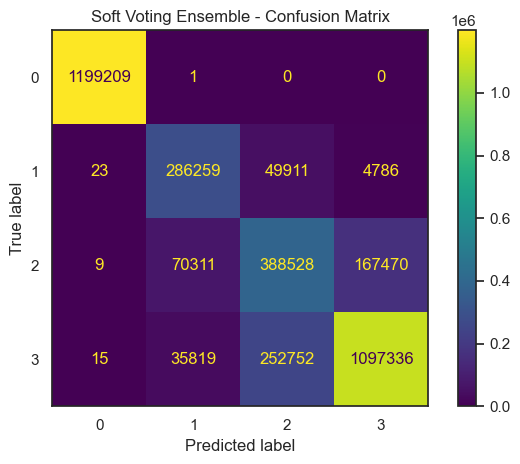

In [ ]:
model_names_soft_vote = [
    "RF",
    "LightGBM",
    "TCN",
    "TCN+MHAL",
    "GAT"
]

# Original validation probabilities
VAL_soft_vote = {
    name_soft_vote: np.asarray(
        val_models_proba[name_soft_vote]
    )
    for name_soft_vote in model_names_soft_vote
}


y_val_soft_vote = np.asarray(y_val).reshape(-1)


# Original test probabilities
TEST_soft_vote = {
    "RF": np.asarray(y_pred_prob_rf),
    "LightGBM": np.asarray(y_pred_prob_lbgm),
    "TCN": np.asarray(predictions_tcn),
    "TCN+MHAL": np.asarray(predictions_tcn_mhal),
    "GAT": np.asarray(GAT_y_prob)
}

y_test_soft_vote = np.asarray(Y_test_t)

if y_test_soft_vote.ndim == 2:
    y_test_soft_vote = np.argmax(
        y_test_soft_vote,
        axis=1
    )
else:
    y_test_soft_vote = y_test_soft_vote.reshape(-1)


# Check shapes
for name_soft_vote in model_names_soft_vote:

    assert VAL_soft_vote[name_soft_vote].shape == (
        len(y_val_soft_vote), 4
    ), f"Validation mismatch: {name_soft_vote}"

    assert TEST_soft_vote[name_soft_vote].shape == (
        len(y_test_soft_vote), 4
    ), f"Test mismatch: {name_soft_vote}"


def evaluate_predictions_soft_vote(
    y_true_soft_vote,
    probabilities_soft_vote
):

    y_pred_soft_vote = probabilities_soft_vote.argmax(axis=1)

    (
        precision_soft_vote,
        recall_soft_vote,
        f1_soft_vote,
        _
    ) = precision_recall_fscore_support(
        y_true_soft_vote,
        y_pred_soft_vote,
        labels=np.arange(4),
        average="macro",
        zero_division=0
    )

    pr_auc_scores_soft_vote = []

    for cl_soft_vote in range(4):

        p_soft_vote, r_soft_vote, _ = precision_recall_curve(
            (y_true_soft_vote == cl_soft_vote).astype(int),
            probabilities_soft_vote[:, cl_soft_vote]
        )

        pr_auc_scores_soft_vote.append(
            auc(r_soft_vote, p_soft_vote)
        )

    return {
        "Recall": recall_soft_vote,
        "Precision": precision_soft_vote,
        "F1-score": f1_soft_vote,
        "PR-AUC": np.mean(pr_auc_scores_soft_vote)
    }


def soft_vote(
    combo_soft_vote,
    probabilities_soft_vote,
    weights_soft_vote=None
):

    if weights_soft_vote is None:

        weights_soft_vote = (
            np.ones(len(combo_soft_vote))
            / len(combo_soft_vote)
        )

    result_soft_vote = np.zeros_like(
        probabilities_soft_vote[combo_soft_vote[0]],
        dtype=np.float64
    )

    for i_soft_vote, name_soft_vote in enumerate(combo_soft_vote):

        if weights_soft_vote.ndim == 1:

            result_soft_vote += (
                weights_soft_vote[i_soft_vote]
                * probabilities_soft_vote[name_soft_vote]
            )

        else:

            result_soft_vote += (
                probabilities_soft_vote[name_soft_vote]
                * weights_soft_vote[i_soft_vote]
            )

    # Class-wise weighting requires row normalization
    if weights_soft_vote.ndim == 2:

        result_soft_vote /= np.clip(
            result_soft_vote.sum(
                axis=1,
                keepdims=True
            ),
            1e-12,
            None
        )

    return result_soft_vote


def calculate_weights_soft_vote(
    combo_soft_vote,
    method_soft_vote
):

    if method_soft_vote == "Equal":

        scores_soft_vote = np.ones(
            len(combo_soft_vote)
        )

    elif method_soft_vote in [
        "Macro F1",
        "Macro Recall"
    ]:

        scores_soft_vote = []

        for name_soft_vote in combo_soft_vote:

            pred_soft_vote = VAL_soft_vote[
                name_soft_vote
            ].argmax(axis=1)

            if method_soft_vote == "Macro F1":

                score_soft_vote = f1_score(
                    y_val_soft_vote,
                    pred_soft_vote,
                    labels=np.arange(4),
                    average="macro",
                    zero_division=0
                )

            else:
                score_soft_vote = recall_score(
                    y_val_soft_vote,
                    pred_soft_vote,
                    labels=np.arange(4),
                    average="macro",
                    zero_division=0
                )

            scores_soft_vote.append(score_soft_vote)

        scores_soft_vote = np.asarray(
            scores_soft_vote
        )

    elif method_soft_vote in [
        "Class F1",
        "Class Recall"
    ]:

        scores_soft_vote = []

        for name_soft_vote in combo_soft_vote:

            pred_soft_vote = VAL_soft_vote[
                name_soft_vote
            ].argmax(axis=1)

            if method_soft_vote == "Class F1":

                score_soft_vote = f1_score(
                    y_val_soft_vote,
                    pred_soft_vote,
                    labels=np.arange(4),
                    average=None,
                    zero_division=0
                )

            else:

                score_soft_vote = recall_score(
                    y_val_soft_vote,
                    pred_soft_vote,
                    labels=np.arange(4),
                    average=None,
                    zero_division=0
                )

            scores_soft_vote.append(score_soft_vote)

        scores_soft_vote = np.vstack(
            scores_soft_vote
        )

    else:
        raise ValueError(
            f"Unknown weighting method: {method_soft_vote}"
        )

    eps_soft_vote = 1e-8

    scores_soft_vote = (
        scores_soft_vote + eps_soft_vote
    )

    if scores_soft_vote.ndim == 1:

        return (
            scores_soft_vote
            / scores_soft_vote.sum()
        )

    return (
        scores_soft_vote
        / scores_soft_vote.sum(
            axis=0,
            keepdims=True
        )
    )


# =========================================================
# STAGE 1: UNWEIGHTED MEAN VOTING
# ALL COMBINATIONS OF 2-5 MODELS
# =========================================================

combinations_soft_vote = [
    combo_soft_vote
    for n_soft_vote in range(
        2,
        len(model_names_soft_vote) + 1
    )
    for combo_soft_vote in itertools.combinations(
        model_names_soft_vote,
        n_soft_vote
    )
]

mean_results_soft_vote = []

for combo_soft_vote in tqdm(
    combinations_soft_vote,
    desc="Mean voting ablation"
):

    probabilities_soft_vote = soft_vote(
        combo_soft_vote,
        VAL_soft_vote
    )

    metrics_soft_vote = evaluate_predictions_soft_vote(
        y_val_soft_vote,
        probabilities_soft_vote
    )

    mean_results_soft_vote.append({
        "Models": " + ".join(combo_soft_vote),
        "N_models": len(combo_soft_vote),
        **metrics_soft_vote
    })


mean_ablation_df_soft_vote = pd.DataFrame(
    mean_results_soft_vote
).sort_values(
    by=["PR-AUC", "Recall"],
    ascending=[False, False]
).reset_index(drop=True)


print("\n=== STAGE 1: MEAN VOTING ABLATION ===")

display(
    mean_ablation_df_soft_vote.round(4)
)


# Best combination based on validation PR-AUC, then recall
best_combo_soft_vote = tuple(
    mean_ablation_df_soft_vote.iloc[0]["Models"].split(" + ")
)

print("\nBest unweighted combination:")
print(" + ".join(best_combo_soft_vote))


print("\nMean voting with all five models:")

display(
    mean_ablation_df_soft_vote[
        mean_ablation_df_soft_vote["N_models"] == 5
    ].round(4)
)

# =========================================================
# STAGE 2: WEIGHTING ABLATION
# BEST COMBINATION FROM STAGE 1
# =========================================================

weighting_methods_soft_vote = [
    "Equal",
    "Macro F1",
    "Macro Recall",
    "Class F1",
    "Class Recall"
]

weight_results_soft_vote = []
selected_weights_soft_vote = {}

for method_soft_vote in tqdm(
    weighting_methods_soft_vote,
    desc="Weighting ablation"
):

    weights_soft_vote = calculate_weights_soft_vote(
        best_combo_soft_vote,
        method_soft_vote
    )

    selected_weights_soft_vote[
        method_soft_vote
    ] = weights_soft_vote

    probabilities_soft_vote = soft_vote(
        best_combo_soft_vote,
        VAL_soft_vote,
        weights_soft_vote
    )

    metrics_soft_vote = evaluate_predictions_soft_vote(
        y_val_soft_vote,
        probabilities_soft_vote
    )

    weight_results_soft_vote.append({
        "Models": " + ".join(best_combo_soft_vote),
        "Weighting": method_soft_vote,
        **metrics_soft_vote
    })


weight_ablation_df_soft_vote = pd.DataFrame(
    weight_results_soft_vote
).sort_values(
    by=["PR-AUC", "Recall"],
    ascending=[False, False]
).reset_index(drop=True)


print("\n=== STAGE 2: WEIGHTING ABLATION ===")

display(
    weight_ablation_df_soft_vote.round(4)
)


# Select best weighting strategy on validation data
best_method_soft_vote = (
    weight_ablation_df_soft_vote.iloc[0]["Weighting"]
)

best_weights_soft_vote = selected_weights_soft_vote[
    best_method_soft_vote
]


print("\nSelected ensemble:")
print("Models:", " + ".join(best_combo_soft_vote))
print("Weighting:", best_method_soft_vote)
print("Weights:\n", best_weights_soft_vote)


# =========================================================
# 3. COMPARE WEIGHTING METHODS ON TEST SET
# =========================================================

test_results_soft_vote = []

for method_soft_vote in weighting_methods_soft_vote:

    probabilities_soft_vote = soft_vote(
        best_combo_soft_vote,
        TEST_soft_vote,
        selected_weights_soft_vote[method_soft_vote]
    )

    metrics_soft_vote = evaluate_predictions_soft_vote(
        y_test_soft_vote,
        probabilities_soft_vote
    )

    test_results_soft_vote.append({
        "Weighting": method_soft_vote,
        **metrics_soft_vote
    })


test_ablation_df_soft_vote = pd.DataFrame(
    test_results_soft_vote
)

print("\n=== TEST SET: WEIGHTING COMPARISON ===")

display(
    test_ablation_df_soft_vote.round(4)
)

# =========================================================
# FINAL TEST EVALUATION OF SELECTED CONFIGURATION
# =========================================================

P_ens_test_soft_vote = soft_vote(
    best_combo_soft_vote,
    TEST_soft_vote,
    best_weights_soft_vote
)

y_pred_ens_soft_vote = P_ens_test_soft_vote.argmax(
    axis=1
)


print("\n=== SELECTED SOFT VOTING ENSEMBLE ===")

print("Models:", " + ".join(best_combo_soft_vote))
print("Weighting:", best_method_soft_vote)


print("\n=== CLASSIFICATION REPORT ===")

print(
    classification_report(
        y_test_soft_vote,
        y_pred_ens_soft_vote,
        labels=np.arange(4),
        digits=4,
        zero_division=0
    )
)


# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test_soft_vote,
    y_pred_ens_soft_vote,
    labels=np.arange(4),
    values_format="d"
)

plt.title("Soft Voting Ensemble - Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
y_pred_prob_soft_vote = P_ens_test_soft_vote
y_pred_labels_soft_vote = y_pred_ens_soft_vote

Y_test_all_soft_vote = np.asarray(y_test_soft_vote).reshape(-1)
Y_test_rs_soft_vote = np.eye(4)[Y_test_all_soft_vote]

F1_macro_soft_vote = []
Rec_macro_soft_vote = []
Pre_macro_soft_vote = []

F1_class_soft_vote = []
Rec_class_soft_vote = []
Pre_class_soft_vote = []
PR_AUC_class_soft_vote = []
PR_AVG_class_soft_vote = []
PR_AUC_Mac_soft_vote = []

average_precisions_soft_vote = []
PRauc_scores_soft_vote = []

F1_macro_soft_vote.append(
    f1_score(
        Y_test_all_soft_vote,
        y_pred_labels_soft_vote,
        average='macro'
    )
)

Rec_macro_soft_vote.append(
    recall_score(
        Y_test_all_soft_vote,
        y_pred_labels_soft_vote,
        average='macro'
    )
)

Pre_macro_soft_vote.append(
    precision_score(
        Y_test_all_soft_vote,
        y_pred_labels_soft_vote,
        average='macro'
    )
)

# === Per-Class Metrics ===
F1_class_soft_vote.append(
    f1_score(
        Y_test_all_soft_vote,
        y_pred_labels_soft_vote,
        average=None,
        labels=np.arange(4)
    )
)

Rec_class_soft_vote.append(
    recall_score(
        Y_test_all_soft_vote,
        y_pred_labels_soft_vote,
        average=None,
        labels=np.arange(4)
    )
)

Pre_class_soft_vote.append(
    precision_score(
        Y_test_all_soft_vote,
        y_pred_labels_soft_vote,
        average=None,
        labels=np.arange(4)
    )
)

for cl_soft_vote in range(4):

    f_pre_soft_vote, f_rec_soft_vote, _ = precision_recall_curve(
        Y_test_rs_soft_vote[:, cl_soft_vote],
        y_pred_prob_soft_vote[:, cl_soft_vote]
    )

    pr_auc_score_soft_vote = auc(
        f_rec_soft_vote,
        f_pre_soft_vote
    )

    ap_score_soft_vote = average_precision_score(
        Y_test_rs_soft_vote[:, cl_soft_vote],
        y_pred_prob_soft_vote[:, cl_soft_vote]
    )

    average_precisions_soft_vote.append(ap_score_soft_vote)
    PRauc_scores_soft_vote.append(pr_auc_score_soft_vote)

PR_AVG_class_soft_vote.append(average_precisions_soft_vote)
PR_AUC_class_soft_vote.append(PRauc_scores_soft_vote)

PR_AVG_scores_mac_soft_vote = np.mean(average_precisions_soft_vote)
PRAUC_mean_soft_vote = np.mean(PRauc_scores_soft_vote)
PR_AUC_Mac_soft_vote.append(PRAUC_mean_soft_vote)

print("Class PR AUC:", PR_AUC_class_soft_vote)
print("Macro PR AUC:", PR_AUC_Mac_soft_vote)


# === Save Results ===
with open("model_soft_voting.txt", "w") as f_soft_vote:

    f_soft_vote.write(
        "Selected Models: " + " + ".join(best_combo_soft_vote) + "\n"
    )
    f_soft_vote.write(
        "Weighting: " + best_method_soft_vote + "\n\n"
    )

    f_soft_vote.write("Macro F1 Measure:")
    f_soft_vote.write(
        ", ".join([f"{score:.4f}" for score in F1_macro_soft_vote]) + "\n"
    )
    f_soft_vote.write(
        f"Mean Macro F1 Measure: {np.mean(F1_macro_soft_vote):.4f}\n"
    )

    f_soft_vote.write("Macro Recall:")
    f_soft_vote.write(
        ", ".join([f"{score:.4f}" for score in Rec_macro_soft_vote]) + "\n"
    )
    f_soft_vote.write(
        f"Mean Macro Recall: {np.mean(Rec_macro_soft_vote):.4f}\n"
    )

    f_soft_vote.write("Macro Precision:")
    f_soft_vote.write(
        ", ".join([f"{score:.4f}" for score in Pre_macro_soft_vote]) + "\n"
    )
    f_soft_vote.write(
        f"Mean Macro Precision: {np.mean(Pre_macro_soft_vote):.4f}\n"
    )

    f_soft_vote.write("Macro PR AUC:")
    f_soft_vote.write(
        ", ".join([f"{score:.4f}" for score in PR_AUC_Mac_soft_vote]) + "\n"
    )
    f_soft_vote.write(
        f"Mean Macro PR AUC: {np.mean(PR_AUC_Mac_soft_vote):.4f}\n"
    )

    f_soft_vote.write("F1 Measure per Class:")
    f_soft_vote.write(
        ", ".join([f"{score}" for score in F1_class_soft_vote]) + "\n\n"
    )

    f_soft_vote.write("Recall per Class:")
    f_soft_vote.write(
        ", ".join([f"{score}" for score in Rec_class_soft_vote]) + "\n\n"
    )

    f_soft_vote.write("Precision per Class:")
    f_soft_vote.write(
        ", ".join([f"{score}" for score in Pre_class_soft_vote]) + "\n\n"
    )

    f_soft_vote.write("PR AUC per Class:")
    f_soft_vote.write(
        ", ".join([f"{score}" for score in PR_AUC_class_soft_vote]) + "\n\n"
    )

    f_soft_vote.write("AVG PR per Class:")
    f_soft_vote.write(
        ", ".join([f"{score}" for score in PR_AVG_class_soft_vote]) + "\n\n"
    )

print("Results saved to model_soft_voting.txt")

Class PR AUC: [[0.999999999854672, 0.8747247712051697, 0.6044177019188939, 0.9171396748150995]]
Macro PR AUC: [np.float64(0.8490705369484588)]
Results saved to model_soft_voting.txt


# Test on External Datasets

## AZT1D

In [ ]:
from joblib import dump, load

X_test_AZT1D, X_feat_test_AZT1D , Y_test_cat_AZT1D, Y_test_AZT1D = load("Data/AZT1D.joblib")

In [ ]:
classes, counts = np.unique(Y_test_AZT1D , return_counts=True)
counts

array([240, 150, 267, 637])

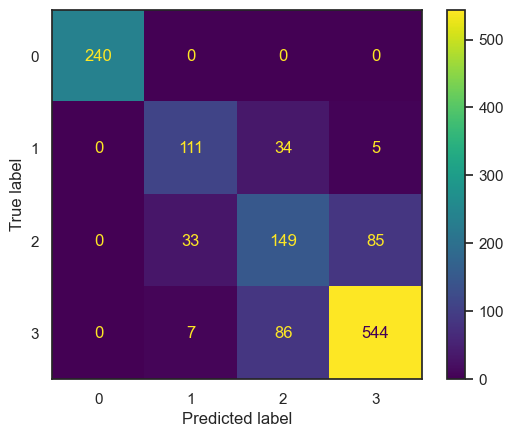


Classification Report:
               precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000       240
           1     0.7351    0.7400    0.7375       150
           2     0.5539    0.5581    0.5560       267
           3     0.8580    0.8540    0.8560       637

    accuracy                         0.8068      1294
   macro avg     0.7868    0.7880    0.7874      1294
weighted avg     0.8074    0.8068    0.8071      1294



In [ ]:
y_pred_prob_rf_AZT1D = model_rf.predict_proba(X_feat_test_AZT1D)
y_pred_labels_rf_AZT1D = model_rf.predict(X_feat_test_AZT1D)

ConfusionMatrixDisplay.from_predictions(Y_test_AZT1D, y_pred_labels_rf_AZT1D)
plt.show()
print("\nClassification Report:\n", classification_report(Y_test_AZT1D, y_pred_labels_rf_AZT1D, digits=4))

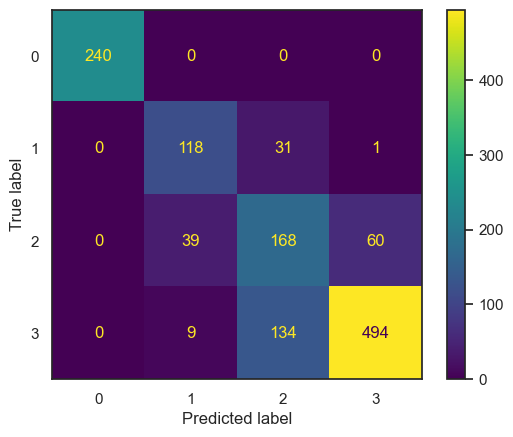


Classification Report:
               precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000       240
           1     0.7108    0.7867    0.7468       150
           2     0.5045    0.6292    0.5600       267
           3     0.8901    0.7755    0.8289       637

    accuracy                         0.7883      1294
   macro avg     0.7764    0.7978    0.7839      1294
weighted avg     0.8101    0.7883    0.7956      1294



In [ ]:
X_test_feat_all_df_AZT1D = pd.DataFrame(X_feat_test_AZT1D, columns=a)

y_pred_labels_lbgm_AZT1D  = model_lbgm.predict(X_test_feat_all_df_AZT1D)
y_pred_prob_lbgm_AZT1D  = model_lbgm.predict_proba(X_test_feat_all_df_AZT1D)
ConfusionMatrixDisplay.from_predictions(Y_test_AZT1D, y_pred_labels_lbgm_AZT1D)
plt.show()

print("\nClassification Report:\n", classification_report(Y_test_AZT1D, y_pred_labels_lbgm_AZT1D, digits=4))

41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step


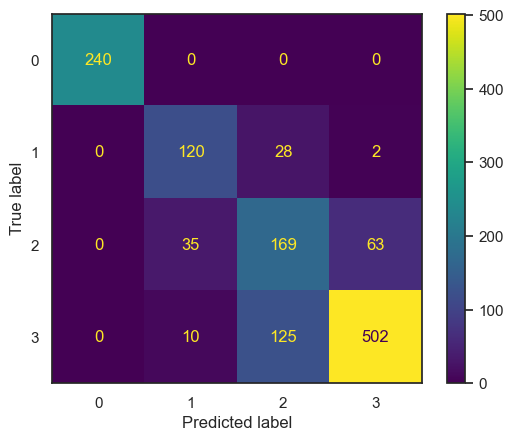

              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000       240
           1     0.7273    0.8000    0.7619       150
           2     0.5248    0.6330    0.5739       267
           3     0.8854    0.7881    0.8339       637

    accuracy                         0.7968      1294
   macro avg     0.7844    0.8053    0.7924      1294
weighted avg     0.8139    0.7968    0.8027      1294



In [ ]:
sns.set_theme(style="white")

predictions_tcn_AZT1D = model_tcn.predict(X_test_AZT1D)

y_pred_tcn_AZT1D = np.argmax(predictions_tcn_AZT1D, axis=1) 
    

final_preds_tcn_AZT1D = y_pred_tcn_AZT1D

y_true_labels_tcn_AZT1D = np.argmax(Y_test_cat_AZT1D, axis=1)
ConfusionMatrixDisplay.from_predictions(y_true_labels_tcn_AZT1D, final_preds_tcn_AZT1D)
plt.show()

report_tcn_AZT1D = classification_report(y_true_labels_tcn_AZT1D, final_preds_tcn_AZT1D, digits=4)
print(report_tcn_AZT1D)

41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step


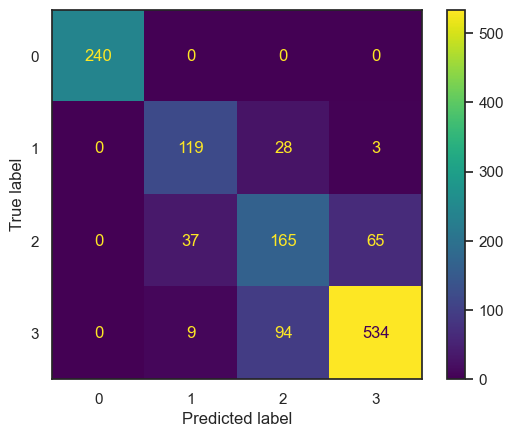

              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000       240
           1     0.7212    0.7933    0.7556       150
           2     0.5749    0.6180    0.5957       267
           3     0.8870    0.8383    0.8620       637

    accuracy                         0.8176      1294
   macro avg     0.7958    0.8124    0.8033      1294
weighted avg     0.8244    0.8176    0.8203      1294



In [56]:
predictions_tcn_mhal_AZT1D = model_tcn_mhal.predict(X_test_AZT1D)

y_pred_tcn_mhal_AZT1D = np.argmax(predictions_tcn_mhal_AZT1D, axis=1) 
    
final_preds_tcn_mhal_AZT1D = y_pred_tcn_mhal_AZT1D

y_true_labels_tcn_mhal_AZT1D = np.argmax(Y_test_cat_AZT1D, axis=1)
ConfusionMatrixDisplay.from_predictions(y_true_labels_tcn_mhal_AZT1D, final_preds_tcn_mhal_AZT1D)
plt.show()

report_fcn_tcn_mhal_AZT1D= classification_report(y_true_labels_tcn_mhal_AZT1D, final_preds_tcn_mhal_AZT1D, digits=4)
print(report_fcn_tcn_mhal_AZT1D)

Building NVGs: 100%|██████████| 1294/1294 [00:00<00:00, 23515.32it/s]


X: (1294, 25, 1)
NVG adjacency: (1294, 25, 25)
Number of graphs: 1294


GATv2 Evaluation: 100%|██████████| 11/11 [00:00<00:00, 27.08batch/s]


              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000       240
           1     0.6982    0.7867    0.7398       150
           2     0.4958    0.6592    0.5659       267
           3     0.9038    0.7520    0.8209       637

    accuracy                         0.7828      1294
   macro avg     0.7744    0.7995    0.7817      1294
weighted avg     0.8136    0.7828    0.7921      1294



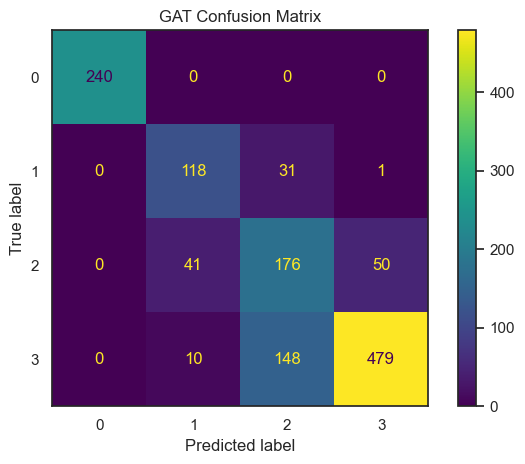

In [134]:
# Ensures reproducibility
seed_value = 42
os.environ["PYTHONHASHSEED"] = str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)
torch.manual_seed(seed_value)


BATCH_SIZE = 128 
SEED = 42
count = 0

_, AZT1D_loader, AZT1D_nvg = create_nvg_dataset(
    X_test_AZT1D, Y_test_cat_AZT1D,
    batch_size=128,
    shuffle=False,
    rand_seed = 42
) 


AZT1D_GAT_y_true = []
AZT1D_GAT_y_pred = []
AZT1D_GAT_y_prob = []

with torch.inference_mode():
    for AZT1D_batch in tqdm(AZT1D_loader, desc="GATv2 Evaluation", unit="batch"):

        AZT1D_logits = GAT_model(AZT1D_batch.to("cpu"))
        AZT1D_probabilities = torch.softmax(AZT1D_logits, dim=1)

        AZT1D_GAT_y_true.append(AZT1D_batch.y.numpy())
        AZT1D_GAT_y_pred.append(AZT1D_probabilities.argmax(dim=1).numpy())
        AZT1D_GAT_y_prob.append(AZT1D_probabilities.numpy())

AZT1D_GAT_y_true = np.concatenate(AZT1D_GAT_y_true)
AZT1D_GAT_y_pred = np.concatenate(AZT1D_GAT_y_pred)
AZT1D_GAT_y_prob = np.concatenate(AZT1D_GAT_y_prob)

print(
    
    classification_report(
        AZT1D_GAT_y_true,
        AZT1D_GAT_y_pred,
        labels=[0, 1, 2, 3],
        digits=4,
        zero_division=0
    )
)

# Confusion matrix
sns.set_theme(style="white")

ConfusionMatrixDisplay.from_predictions(
    AZT1D_GAT_y_true,
    AZT1D_GAT_y_pred,
    labels=[0, 1, 2, 3],
    values_format="d"
)

plt.title(f"GAT Confusion Matrix")
plt.tight_layout()
plt.show()

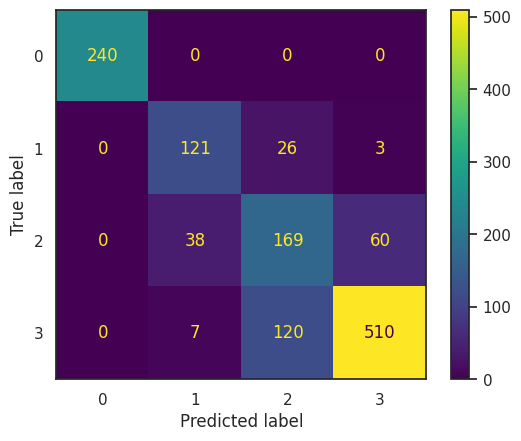

              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000       240
           1     0.7289    0.8067    0.7658       150
           2     0.5365    0.6330    0.5808       267
           3     0.8901    0.8006    0.8430       637

    accuracy                         0.8037      1294
   macro avg     0.7889    0.8101    0.7974      1294
weighted avg     0.8188    0.8037    0.8090      1294



In [ ]:
X_meta_test_AZT1D = np.hstack([y_pred_prob_lbgm_AZT1D,predictions_tcn_AZT1D, predictions_tcn_mhal_AZT1D]) 
P_ens_test_AZT1D = meta_LGBM_TCN_TMHAL.predict_proba(X_meta_test_AZT1D)
y_pred_AZT1D = P_ens_test_AZT1D.argmax(axis=1)

y_true_labels_AZT1D = np.argmax(Y_test_cat_AZT1D, axis=1)
ConfusionMatrixDisplay.from_predictions(y_true_labels_AZT1D,y_pred_AZT1D)
plt.show()

report_meta_AZT1D = classification_report(y_true_labels_AZT1D, y_pred_AZT1D, digits=4)
print(report_meta_AZT1D)

In [ ]:
lower_CI = []
upper_CI = []
F1_macro = []
Rec_macro = []
Pre_macro = []
PR_AUC_macro = []

F1_class = []
Rec_class = []
Pre_class = []
PR_AUC_class = []
PR_AVG_class = []
PR_AUC_Mac = []

average_precisions = []
PRauc_scores = []

y_pred_prob= P_ens_test_AZT1D
y_pred_labels = y_pred_AZT1D

Y_test_all = Y_test_AZT1D
Y_test_rs = Y_test_cat_AZT1D

# Predict class labels

f1_score_mac = f1_score(Y_test_all, y_pred_labels, average='macro')
F1_macro.append(f1_score_mac)

rec_scores_mac = recall_score(Y_test_all, y_pred_labels, average='macro')
Rec_macro.append(rec_scores_mac)

pre_scores_mac = precision_score(Y_test_all, y_pred_labels, average='macro')
Pre_macro.append(pre_scores_mac)

f1_scores = f1_score(Y_test_all, y_pred_labels, average=None, labels=np.arange(4))
F1_class.append(f1_scores)

rec_scores = recall_score(Y_test_all, y_pred_labels, average=None, labels=np.arange(4))
Rec_class.append(rec_scores)

pre_scores = precision_score(Y_test_all, y_pred_labels, average=None, labels=np.arange(4))
Pre_class.append(pre_scores)

classes = set(Y_test_all)
for n_cl, cl in enumerate(classes):  
        f_pre, f_rec, t = precision_recall_curve(Y_test_rs[:, cl], y_pred_prob[:, cl])
        sorted_indices = np.argsort(f_rec)
        pr_auc_scores = auc(f_rec, f_pre)
        ap_score = average_precision_score(Y_test_rs[:, cl], y_pred_prob[:, cl])
        average_precisions.append(ap_score)
        PRauc_scores.append(pr_auc_scores)

PR_AVG_class.append(average_precisions)
PR_AVG_scores_mac = np.mean(average_precisions)


PR_AUC_class.append(PRauc_scores)
PRAUC_mean = np.mean(PRauc_scores)
PR_AUC_Mac.append(PRAUC_mean)

print(f"Class PR AUC: {PR_AUC_class}")
print(f"Mac PR AUC: ({PR_AUC_Mac})")



with open("model_stack_AZT1D.txt", "w") as f:

    f.write("Macro F1 Measure:")
    f.write(", ".join([f"{score:.4f}" for score in F1_macro]) + "\n")
    f.write(f"Mean Macro F1 Measure: {np.mean(F1_macro):.4f}" +"\n")

    f.write("Macro Recall:")
    f.write(", ".join([f"{score:.4f}" for score in Rec_macro]) + "\n")
    f.write(f"Mean Macro Recall: {np.mean(Rec_macro):.4f}" +"\n")

    f.write("Macro Precision:")
    f.write(", ".join([f"{score:.4f}" for score in Pre_macro]) + "\n")
    f.write(f"Mean Macro Precision: {np.mean(Pre_macro):.4f}" +"\n")

    f.write("Macro PR AUC:")
    f.write(", ".join([f"{score:.4f}" for score in PR_AUC_Mac]) + "\n")
    f.write(f"Mean Macro PR AUC: {np.mean(PR_AUC_Mac):.4f}" +"\n")

    f.write("F1 Measure per Class:")
    f.write(", ".join([f"{score}" for score in F1_class]) + "\n\n")

    f.write("Recall per Class:")
    f.write(", ".join([f"{score}" for score in Rec_class]) + "\n\n")

    f.write("Precision per Class:") 
    f.write(", ".join([f"{score}" for score in Pre_class]) + "\n\n")

    f.write("PR AUC per Class:")
    f.write(", ".join([f"{score}" for score in PR_AUC_class]) + "\n\n")

    f.write("AVG PR per Class:")
    f.write(", ".join([f"{score}" for score in PR_AVG_class]) + "\n\n")

Macro recall weights:
RF: 0.3300
TCN: 0.3351
TCN+MHAL: 0.3349


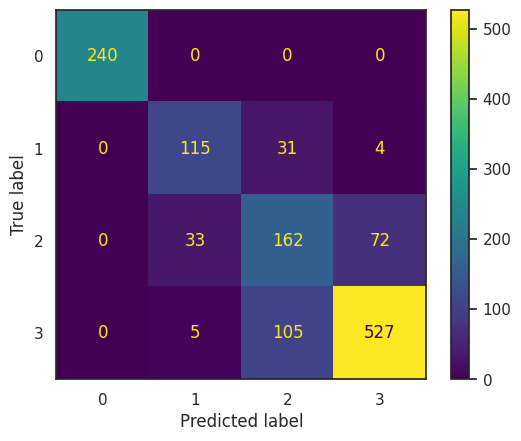

              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000       240
           1     0.7516    0.7667    0.7591       150
           2     0.5436    0.6067    0.5735       267
           3     0.8740    0.8273    0.8500       637

    accuracy                         0.8068      1294
   macro avg     0.7923    0.8002    0.7956      1294
weighted avg     0.8150    0.8068    0.8102      1294

Macro Recall: 0.8002


In [ ]:
model_names_AZT1D = ["RF", "TCN", "TCN+MHAL"]

recall_weights_AZT1D = np.array([
    recall_score(
        y_val_soft_vote,
        VAL_soft_vote[name_AZT1D].argmax(axis=1),
        labels=np.arange(4),
        average="macro",
        zero_division=0
    )
    for name_AZT1D in model_names_AZT1D
])

recall_weights_AZT1D = recall_weights_AZT1D / recall_weights_AZT1D.sum()

print("Macro recall weights:")
for name, weight in zip(model_names_AZT1D, recall_weights_AZT1D):
    print(f"{name}: {weight:.4f}")


all_proba_AZT1D = np.average(
    np.stack([
        y_pred_prob_rf_AZT1D,
        predictions_tcn_AZT1D,
        predictions_tcn_mhal_AZT1D
    ], axis=0),
    axis=0,
    weights=recall_weights_AZT1D
)

y_pred_all_AZT1D = np.argmax(all_proba_AZT1D, axis=1)


y_true_labels_AZT1D = np.argmax(Y_test_cat_AZT1D, axis=1)

ConfusionMatrixDisplay.from_predictions(
    y_true_labels_AZT1D,
    y_pred_all_AZT1D
)
plt.show()

report_sv_AZT1D = classification_report(
    y_true_labels_AZT1D,
    y_pred_all_AZT1D,
    digits=4
)
print(report_sv_AZT1D)

print(
    "Macro Recall:",
    f"{recall_score(y_true_labels_AZT1D, y_pred_all_AZT1D, average='macro'):.4f}"
)

In [ ]:
# True labels (one-hot encoded)
Y_true_AZT1D = np.asarray(Y_test_cat_AZT1D)

# Predicted probabilities from each model
model_probabilities_AZT1D = {
    "Random Forest": y_pred_prob_rf_AZT1D,
    "LightGBM": y_pred_prob_lbgm_AZT1D,
    "TCN": predictions_tcn_AZT1D,
    "TCN+MHAL": predictions_tcn_mhal_AZT1D,
    "GAT": AZT1D_GAT_y_prob,
    "Meta Stacking": P_ens_test_AZT1D,
    "Soft Voting": all_proba_AZT1D 
}

PR_AUC_results_AZT1D = []

for model_name, y_pred_prob in model_probabilities_AZT1D.items():

    y_pred_prob = np.asarray(y_pred_prob)

    assert y_pred_prob.shape == Y_true_AZT1D.shape, (
        f"{model_name}: {y_pred_prob.shape} != {Y_true_AZT1D.shape}"
    )

    PRauc_scores = []

    for cl in range(4):

        precision, recall, _ = precision_recall_curve(
            Y_true_AZT1D[:, cl],
            y_pred_prob[:, cl]
        )

        pr_auc = auc(recall, precision)
        PRauc_scores.append(pr_auc)

    PR_AUC_results_AZT1D.append({
        "Model": model_name,
        "Metric": "PR-AUC",
        "Macro-avg": np.mean(PRauc_scores),
        "Class 0": PRauc_scores[0],
        "Class 1": PRauc_scores[1],
        "Class 2": PRauc_scores[2],
        "Class 3": PRauc_scores[3]
    })

PR_AUC_table_AZT1D = pd.DataFrame(PR_AUC_results_AZT1D)

display(PR_AUC_table_AZT1D.round(4))

,Model,Metric,Macro-avg,Class 0,Class 1,Class 2,Class 3
0,Random Forest,PR-AUC,0.8304,1.0,0.8268,0.5655,0.9291
1,LightGBM,PR-AUC,0.8255,1.0,0.8311,0.5419,0.9288
2,TCN,PR-AUC,0.8302,1.0,0.8332,0.5593,0.9284
3,TCN+MHAL,PR-AUC,0.8360,1.0,0.8302,0.5800,0.9339
4,GAT,PR-AUC,0.8251,1.0,0.8241,0.5428,0.9332
5,Meta Stacking,PR-AUC,0.8456,1.0,0.8374,0.6123,0.9326
6,Soft Voting,PR-AUC,0.8398,1.0,0.8367,0.5894,0.9332


## T1 UDM

In [ ]:
X_test_T1DUOM, X_feat_test_T1DUOM, Y_test_cat_T1DUOM, Y_test_T1DUOM = load("Data/T1DUOM.joblib")

In [ ]:
classes, counts = np.unique(Y_test_T1DUOM, return_counts=True)
counts

array([11361,  4242,  7862, 17506])

In [70]:
Y_test_T1DUOM.shape

(40971,)

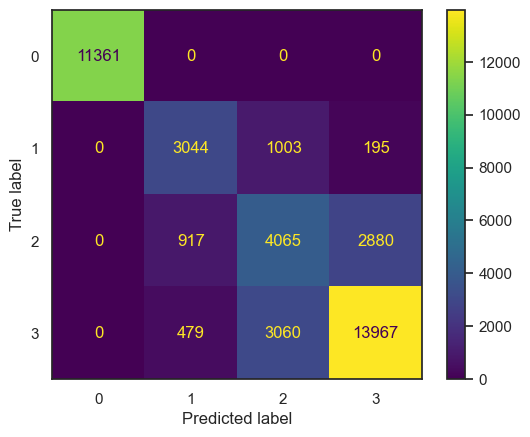


Classification Report:
               precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000     11361
           1     0.6856    0.7176    0.7012      4242
           2     0.5001    0.5170    0.5084      7862
           3     0.8196    0.7978    0.8086     17506

    accuracy                         0.7917     40971
   macro avg     0.7513    0.7581    0.7546     40971
weighted avg     0.7944    0.7917    0.7929     40971



In [ ]:
y_pred_prob_rf_T1DUOM  = model_rf.predict_proba(X_feat_test_T1DUOM)
y_pred_labels_rf_T1DUOM = model_rf.predict(X_feat_test_T1DUOM)

ConfusionMatrixDisplay.from_predictions(Y_test_T1DUOM, y_pred_labels_rf_T1DUOM)
plt.show()
print("\nClassification Report:\n", classification_report(Y_test_T1DUOM, y_pred_labels_rf_T1DUOM , digits=4))

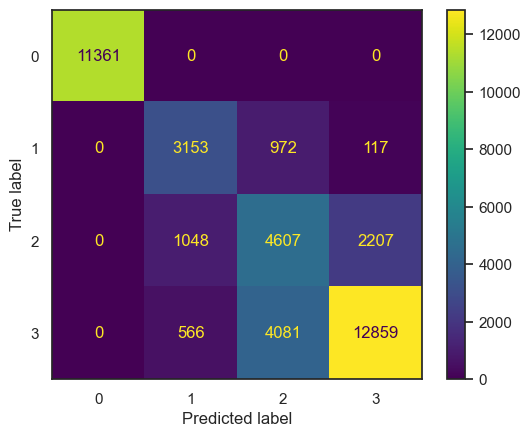


Classification Report:
               precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000     11361
           1     0.6614    0.7433    0.7000      4242
           2     0.4769    0.5860    0.5259      7862
           3     0.8469    0.7345    0.7867     17506

    accuracy                         0.7806     40971
   macro avg     0.7463    0.7660    0.7531     40971
weighted avg     0.7992    0.7806    0.7868     40971



In [ ]:
X_test_feat_all_df_T1DUOM = pd.DataFrame(X_feat_test_T1DUOM , columns=a)

y_pred_labels_lbgm_T1DUOM  = model_lbgm.predict(X_test_feat_all_df_T1DUOM )
y_pred_prob_lbgm_T1DUOM   = model_lbgm.predict_proba(X_test_feat_all_df_T1DUOM )
ConfusionMatrixDisplay.from_predictions(Y_test_T1DUOM , y_pred_labels_lbgm_T1DUOM )
plt.show()

print("\nClassification Report:\n", classification_report(Y_test_T1DUOM , y_pred_labels_lbgm_T1DUOM , digits=4))

1281/1281 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step


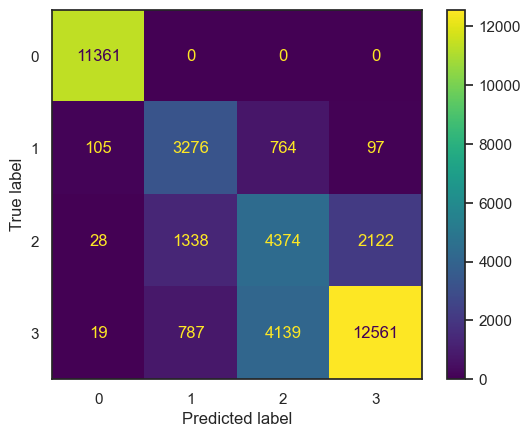

              precision    recall  f1-score   support

           0     0.9868    1.0000    0.9934     11361
           1     0.6066    0.7723    0.6795      4242
           2     0.4715    0.5563    0.5104      7862
           3     0.8499    0.7175    0.7781     17506

    accuracy                         0.7706     40971
   macro avg     0.7287    0.7615    0.7403     40971
weighted avg     0.7900    0.7706    0.7762     40971



In [ ]:
sns.set_theme(style="white")

predictions_tcn_T1DUOM  = model_tcn.predict(X_test_T1DUOM )

y_pred_tcn_T1DUOM  = np.argmax(predictions_tcn_T1DUOM , axis=1) 


final_preds_tcn_T1DUOM  = y_pred_tcn_T1DUOM 

y_true_labels_tcn_T1DUOM  = np.argmax(Y_test_cat_T1DUOM , axis=1)
ConfusionMatrixDisplay.from_predictions(y_true_labels_tcn_T1DUOM , final_preds_tcn_T1DUOM )
plt.show()

report_tcn_T1DUOM  = classification_report(y_true_labels_tcn_T1DUOM , final_preds_tcn_T1DUOM , digits=4)
print(report_tcn_T1DUOM )

1281/1281 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step


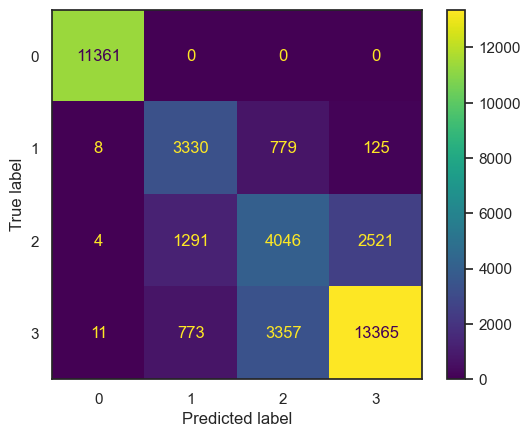

              precision    recall  f1-score   support

           0     0.9980    1.0000    0.9990     11361
           1     0.6174    0.7850    0.6912      4242
           2     0.4945    0.5146    0.5044      7862
           3     0.8347    0.7635    0.7975     17506

    accuracy                         0.7835     40971
   macro avg     0.7361    0.7658    0.7480     40971
weighted avg     0.7922    0.7835    0.7861     40971



In [75]:
predictions_tcn_mhal_T1DUOM = model_tcn_mhal.predict(X_test_T1DUOM )

y_pred_tcn_mhal_T1DUOM  = np.argmax(predictions_tcn_mhal_T1DUOM , axis=1) 
    
final_preds_tcn_mhal_T1DUOM = y_pred_tcn_mhal_T1DUOM 

y_true_labels_tcn_mhal_T1DUOM  = np.argmax(Y_test_cat_T1DUOM , axis=1)
ConfusionMatrixDisplay.from_predictions(y_true_labels_tcn_mhal_T1DUOM , final_preds_tcn_mhal_T1DUOM )
plt.show()

report_fcn_tcn_mhal_T1DUOM = classification_report(y_true_labels_tcn_mhal_T1DUOM , final_preds_tcn_mhal_T1DUOM , digits=4)
print(report_fcn_tcn_mhal_T1DUOM )

Building NVGs: 100%|██████████| 40971/40971 [00:01<00:00, 24842.80it/s]


X: (40971, 25, 1)
NVG adjacency: (40971, 25, 25)
Number of graphs: 40971


GATv2 Evaluation: 100%|██████████| 321/321 [00:14<00:00, 22.77batch/s]


              precision    recall  f1-score   support

           0     0.9526    1.0000    0.9757     11361
           1     0.6085    0.6966    0.6496      4242
           2     0.4639    0.5829    0.5167      7862
           3     0.8567    0.7003    0.7707     17506

    accuracy                         0.7605     40971
   macro avg     0.7205    0.7450    0.7282     40971
weighted avg     0.7823    0.7605    0.7663     40971



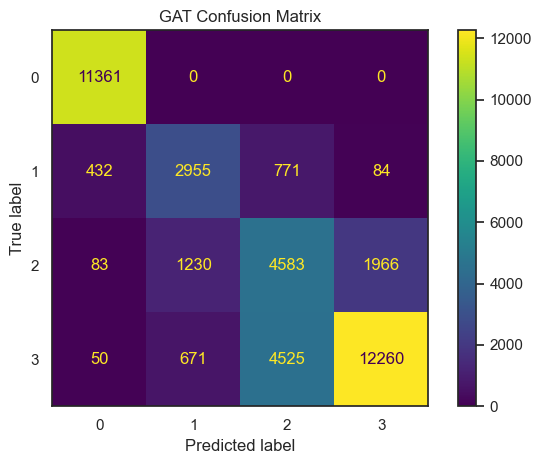

In [ ]:
# Ensures reproducibility
seed_value = 42

os.environ["PYTHONHASHSEED"] = str(seed_value)

random.seed(seed_value)
np.random.seed(seed_value)

torch.manual_seed(seed_value)


count = 0

_, T1DUOM_loader, T1DUOM_nvg = create_nvg_dataset(
    X_test_T1DUOM, Y_test_cat_T1DUOM,
    batch_size=128,
    shuffle=False,
    rand_seed = 42
) 


T1DUOM_GAT_y_true = []
T1DUOM_GAT_y_pred = []
T1DUOM_GAT_y_prob = []

with torch.inference_mode():
    for T1DUOM_batch in tqdm(T1DUOM_loader, desc="GATv2 Evaluation", unit="batch"):

        T1DUOM_logits = GAT_model(T1DUOM_batch.to("cpu"))
        T1DUOM_probabilities = torch.softmax(T1DUOM_logits, dim=1)

        T1DUOM_GAT_y_true.append(T1DUOM_batch.y.numpy())
        T1DUOM_GAT_y_pred.append(T1DUOM_probabilities.argmax(dim=1).numpy())
        T1DUOM_GAT_y_prob.append(T1DUOM_probabilities.numpy())

T1DUOM_GAT_y_true = np.concatenate(T1DUOM_GAT_y_true)
T1DUOM_GAT_y_pred = np.concatenate(T1DUOM_GAT_y_pred)
T1DUOM_GAT_y_prob = np.concatenate(T1DUOM_GAT_y_prob)

print(
    
    classification_report(
        T1DUOM_GAT_y_true,
        T1DUOM_GAT_y_pred,
        labels=[0, 1, 2, 3],
        digits=4,
        zero_division=0
    )
)

# Confusion matrix
sns.set_theme(style="white")

ConfusionMatrixDisplay.from_predictions(
    T1DUOM_GAT_y_true,
    T1DUOM_GAT_y_pred,
    labels=[0, 1, 2, 3],
    values_format="d"
)

plt.title(f"GAT Confusion Matrix")
plt.tight_layout()
plt.show()

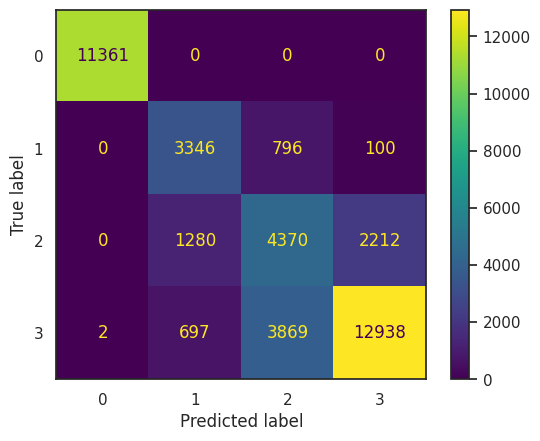

              precision    recall  f1-score   support

           0     0.9998    1.0000    0.9999     11361
           1     0.6286    0.7888    0.6996      4242
           2     0.4837    0.5558    0.5173      7862
           3     0.8484    0.7391    0.7900     17506

    accuracy                         0.7814     40971
   macro avg     0.7401    0.7709    0.7517     40971
weighted avg     0.7976    0.7814    0.7865     40971



In [123]:
X_meta_test_T1DUOM = np.hstack([y_pred_prob_lbgm_T1DUOM ,predictions_tcn_T1DUOM, predictions_tcn_mhal_T1DUOM]) 
P_ens_test_T1DUOM  = meta_LGBM_TCN_TMHAL.predict_proba(X_meta_test_T1DUOM)
y_pred_T1DUOM  = P_ens_test_T1DUOM .argmax(axis=1)

y_true_labels_T1DUOM = np.argmax(Y_test_cat_T1DUOM , axis=1)
ConfusionMatrixDisplay.from_predictions(y_true_labels_T1DUOM ,y_pred_T1DUOM )
plt.show()

report_fcn_T1DUOM  = classification_report(y_true_labels_T1DUOM , y_pred_T1DUOM , digits=4)
print(report_fcn_T1DUOM)

In [ ]:
lower_CI = []
upper_CI = []
F1_macro = []
Rec_macro = []
Pre_macro = []
PR_AUC_macro = []

F1_class = []
Rec_class = []
Pre_class = []
PR_AUC_class = []
PR_AVG_class = []
PR_AUC_Mac = []

average_precisions = []
PRauc_scores = []



y_pred_prob= P_ens_test_T1DUOM
y_pred_labels = y_pred_T1DUOM

Y_test_all = Y_test_T1DUOM
Y_test_rs = Y_test_cat_T1DUOM

# Predict class labels

f1_score_mac = f1_score(Y_test_all, y_pred_labels, average='macro')
F1_macro.append(f1_score_mac)

rec_scores_mac = recall_score(Y_test_all, y_pred_labels, average='macro')
Rec_macro.append(rec_scores_mac)

pre_scores_mac = precision_score(Y_test_all, y_pred_labels, average='macro')
Pre_macro.append(pre_scores_mac)

f1_scores = f1_score(Y_test_all, y_pred_labels, average=None, labels=np.arange(4))
F1_class.append(f1_scores)

rec_scores = recall_score(Y_test_all, y_pred_labels, average=None, labels=np.arange(4))
Rec_class.append(rec_scores)

pre_scores = precision_score(Y_test_all, y_pred_labels, average=None, labels=np.arange(4))
Pre_class.append(pre_scores)

classes = set(Y_test_all)
for n_cl, cl in enumerate(classes):  
        f_pre, f_rec, t = precision_recall_curve(Y_test_rs[:, cl], y_pred_prob[:, cl])
        sorted_indices = np.argsort(f_rec)
        pr_auc_scores = auc(f_rec, f_pre)
        ap_score = average_precision_score(Y_test_rs[:, cl], y_pred_prob[:, cl])
        average_precisions.append(ap_score)
        PRauc_scores.append(pr_auc_scores)

PR_AVG_class.append(average_precisions)
PR_AVG_scores_mac = np.mean(average_precisions)


PR_AUC_class.append(PRauc_scores)
PRAUC_mean = np.mean(PRauc_scores)
PR_AUC_Mac.append(PRAUC_mean)

print(f"Class PR AUC: {PR_AUC_class}")
print(f"Mac PR AUC: ({PR_AUC_Mac})")


with open("model_stack_T1DUOM.txt", "w") as f:

    f.write("Macro F1 Measure:")
    f.write(", ".join([f"{score:.4f}" for score in F1_macro]) + "\n")
    f.write(f"Mean Macro F1 Measure: {np.mean(F1_macro):.4f}" +"\n")

    f.write("Macro Recall:")
    f.write(", ".join([f"{score:.4f}" for score in Rec_macro]) + "\n")
    f.write(f"Mean Macro Recall: {np.mean(Rec_macro):.4f}" +"\n")

    f.write("Macro Precision:")
    f.write(", ".join([f"{score:.4f}" for score in Pre_macro]) + "\n")
    f.write(f"Mean Macro Precision: {np.mean(Pre_macro):.4f}" +"\n")

    f.write("Macro PR AUC:")
    f.write(", ".join([f"{score:.4f}" for score in PR_AUC_Mac]) + "\n")
    f.write(f"Mean Macro PR AUC: {np.mean(PR_AUC_Mac):.4f}" +"\n")

    f.write("F1 Measure per Class:")
    f.write(", ".join([f"{score}" for score in F1_class]) + "\n\n")

    f.write("Recall per Class:")
    f.write(", ".join([f"{score}" for score in Rec_class]) + "\n\n")

    f.write("Precision per Class:") 
    f.write(", ".join([f"{score}" for score in Pre_class]) + "\n\n")

    f.write("PR AUC per Class:")
    f.write(", ".join([f"{score}" for score in PR_AUC_class]) + "\n\n")

    f.write("AVG PR per Class:")
    f.write(", ".join([f"{score}" for score in PR_AVG_class]) + "\n\n")

Macro recall weights:
RF: 0.3300
TCN: 0.3351
TCN+MHAL: 0.3349


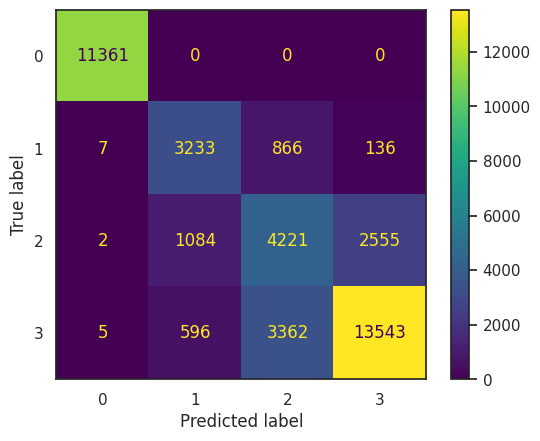

              precision    recall  f1-score   support

           0     0.9988    1.0000    0.9994     11361
           1     0.6581    0.7621    0.7063      4242
           2     0.4996    0.5369    0.5176      7862
           3     0.8342    0.7736    0.8028     17506

    accuracy                         0.7898     40971
   macro avg     0.7477    0.7682    0.7565     40971
weighted avg     0.7974    0.7898    0.7926     40971

Macro Recall: 0.7682


In [ ]:
model_names_T1DUOM = ["RF", "TCN", "TCN+MHAL"]

recall_weights_T1DUOM = np.array([
    recall_score(
        y_val_soft_vote,
        VAL_soft_vote[name_T1DUOM].argmax(axis=1),
        labels=np.arange(4),
        average="macro",
        zero_division=0
    )
    for name_T1DUOM in model_names_T1DUOM
])

recall_weights_T1DUOM = recall_weights_T1DUOM / recall_weights_T1DUOM.sum()

print("Macro recall weights:")
for name, weight in zip(model_names_T1DUOM, recall_weights_T1DUOM):
    print(f"{name}: {weight:.4f}")


all_proba_T1DUOM = np.average(
    np.stack([
        y_pred_prob_rf_T1DUOM,
        predictions_tcn_T1DUOM,
        predictions_tcn_mhal_T1DUOM
    ], axis=0),
    axis=0,
    weights=recall_weights_T1DUOM
)

y_pred_all_T1DUOM = np.argmax(all_proba_T1DUOM, axis=1)

y_true_labels_T1DUOM = np.argmax(Y_test_cat_T1DUOM, axis=1)

ConfusionMatrixDisplay.from_predictions(
    y_true_labels_T1DUOM,
    y_pred_all_T1DUOM
)
plt.show()

report_sv_T1DUOM= classification_report(
    y_true_labels_T1DUOM,
    y_pred_all_T1DUOM,
    digits=4
)
print(report_sv_T1DUOM)

print(
    "Macro Recall:",
    f"{recall_score(y_true_labels_T1DUOM, y_pred_all_T1DUOM, average='macro'):.4f}"
)

In [ ]:
# True labels (one-hot encoded)
Y_true_T1DUOM = np.asarray(Y_test_cat_T1DUOM)

# Predicted probabilities from each model
model_probabilities_T1DUOM= {
    "Random Forest": y_pred_prob_rf_T1DUOM,
    "LightGBM": y_pred_prob_lbgm_T1DUOM,
    "TCN": predictions_tcn_T1DUOM,
    "TCN+MHAL": predictions_tcn_mhal_T1DUOM,
    "GAT": T1DUOM_GAT_y_prob,
    "Meta Stacking": P_ens_test_T1DUOM,
    "Soft Voting": all_proba_T1DUOM 
}

PR_AUC_results_T1DUOM = []

for model_name, y_pred_prob in model_probabilities_T1DUOM.items():

    y_pred_prob = np.asarray(y_pred_prob)

    assert y_pred_prob.shape == Y_true_T1DUOM.shape, (
        f"{model_name}: {y_pred_prob.shape} != {Y_true_T1DUOM.shape}"
    )

    PRauc_scores = []

    for cl in range(4):

        precision, recall, _ = precision_recall_curve(
            Y_true_T1DUOM[:, cl],
            y_pred_prob[:, cl]
        )

        pr_auc = auc(recall, precision)
        PRauc_scores.append(pr_auc)

    PR_AUC_results_T1DUOM.append({
        "Model": model_name,
        "Metric": "PR-AUC",
        "Macro-avg": np.mean(PRauc_scores),
        "Class 0": PRauc_scores[0],
        "Class 1": PRauc_scores[1],
        "Class 2": PRauc_scores[2],
        "Class 3": PRauc_scores[3]
    })

PR_AUC_table_T1DUOM = pd.DataFrame(PR_AUC_results_T1DUOM)

display(PR_AUC_table_T1DUOM.round(4))

,Model,Metric,Macro-avg,Class 0,Class 1,Class 2,Class 3
0,Random Forest,PR-AUC,0.7850,1.0,0.7591,0.4954,0.8856
1,LightGBM,PR-AUC,0.7838,1.0,0.7578,0.4911,0.8864
2,TCN,PR-AUC,0.7734,1.0,0.7405,0.4678,0.8852
3,TCN+MHAL,PR-AUC,0.7815,1.0,0.7618,0.4801,0.8843
4,GAT,PR-AUC,0.7683,1.0,0.7204,0.4678,0.8852
5,Meta Stacking,PR-AUC,0.7865,1.0,0.7648,0.4931,0.8881
6,Soft Voting,PR-AUC,0.7888,1.0,0.7685,0.4978,0.8887
